---

# DSC LOGIKA UI 2026: Credit Risk Prediction

*Predicting 90+ DPD within 12 months of origination for Indonesian consumer loans, scored by the KS statistic.*

---

## TeamName (DSCxxxx)

- Name 1 (Role)
- Name 2
- Name 3

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Feature Engineering**](#4)
5. [**Validation Strategy**](#5)
6. [**Gradient Boosting Models**](#6)
7. [**Foundation and Neural Models**](#7)
8. [**Ensemble and KS Stability**](#8)
9. [**Submission**](#9)


---

# Introduction <a name="1"></a>

---

## Overview

*Credit risk is a central challenge in consumer lending. A lender has to judge, at the moment of the loan decision, whether an application is likely to run into serious repayment difficulty using only the information available at that time.*

*This competition frames the problem on a multi-table Indonesian consumer lending dataset. Each selected loan has a 12-month term, and the goal is to rank applications by their risk of reaching 90 or more days past due within 12 months of origination.*

## Aim

*Build a leak-free scoring pipeline that aggregates six behavioural tables into one row per application and produces a risk score with maximal and stable KS separation on both the public and the private leaderboard.*

## Metric

***The Kolmogorov-Smirnov (KS) statistic** measures the largest vertical gap between the cumulative score distributions of bad loans and good loans. It depends only on the ranking of scores, so calibration does not matter and rank-averaging is a safe way to blend models.*

$$KS = \max_s \left| F_1(s) - F_0(s) \right|$$

## Dataset

*Data sourced from the Kaggle competition DSC LOGIKA UI 2026.*

*The training set contains 70,000 selected applications (13.58% bad) and the test set contains 30,000. Every customer has exactly one selected application, and train and test customers are disjoint. About 30% of customers in both splits are thin-file, with no previous applications, repayment history or account data.*

*The dataset is used to engineer customer-level features that respect the `decision_datetime` information cutoff.*

**Attributes**

1.  `train/test_applications`  : Selected loan (amount, 12-month term, rate tier, installment, purpose)
2.  `customer_profiles`        : Age, region, employment, tenure, declared income, dependents, housing
3.  `previous_applications`    : Historical applications with decision, approved amount and rate
4.  `repayment_history`        : Installment-level amounts, payment dates and days past due
5.  `account_behavior`         : Monthly balances, inflows, outflows and low-balance days
6.  `bureau_observations`      : Up to three bureau reports per application (score, utilization, inquiries)
7.  `ecommerce_transactions`   : Item-level orders with category, payment method and status

**Target**
 `target`       : 1 if the loan reaches 90+ DPD within 12 months, 0 otherwise

## Approach: Behavioural Features + GBDT and Tabular Foundation Model Ensemble

*The approach aggregates every auxiliary table to the customer level with explicit cutoff filters. Window lengths are chosen from the exploratory analysis: repayment lateness is a stable trait, so full-history ratios are used, while e-commerce activity and cash-flow stress ramp up in the 3-4 months before the application, so recent-versus-baseline acceleration features are used.*

*Version 2 adds 38 features found by a residual analysis of the version 1 out-of-fold predictions. They cover lateness severity (how many months a late installment stays unpaid), first-installment and latest-loan behaviour, non-income inflows, bureau score trend, cancellations and night-time orders. The same analysis showed that risk is close to additive in log-odds across the signal families, so every tree library is run twice: a deep variant (as in version 1) and a shallow variant.*

*Version 6 starts from version 5 (public leaderboard 0.561), whose jump came from one new measurement: the unit price a customer pays relative to the typical price of the same category. Three independent residual sweeps of the version 5 predictions (39 per-row attributes from every table, 29 price variants, and 301 generic DFS columns) found nothing else above noise, so version 6 does not add features. It makes the pipeline stricter and widens the model side. The category price reference is now built only from purchases dated before the application's decision month, so every application is normalised with prices that were already observed. The TabM input map is fitted inside each fold. The foundation models get a fair test: TabPFN-3.5 now sees the same hand-made features as the trees, and EXAONE receives exactly its 100-column limit. A second TabM with periodic embeddings joins the blend.*

*Version 7 kept the version 6 features and spent a full Kaggle T4 x2 session on the model side. Its blend reached 0.5268 on held-out halves (version 6: 0.5263) with a test rank correlation of 0.9995 to version 6, so it was the same submission. Causilo ran for the first time (0.5226), native TabPFN-Rel scored 0.4917 and EXAONE stopped at its 56,000-row context because the T4 could not hold it.*

*Version 8 tried new training rows instead of new columns: 81,702 earlier loans of the same customers whose 12-month outcome was already observed, rebuilt as of their own decision time. Trained on identical folds, the trees and TabM moved by -0.0026 to +0.0015 KS with them, every bootstrap interval crossing zero, and an independent audit (`eda/v8_review`) showed that their snapshots cannot be reconstructed exactly (a payment ledger is only known at the selected cutoff) and that their e-commerce risk mapping differs from the selected loans. The run also died inside TabICLv2 after four hours. Its saved predictions gave a held-out blend KS of 0.5277 and a public score of about 0.561, the same as versions 5 and 6.*

*Version 9 is the consolidation. A fresh offline search (`eda/90` to `eda/96`) looked for any information the version 8 blend leaves unused and found none: no links between customers through any exact shared value, no event type in any time window whose count still correlates with the residual (1,142 score tests, largest |z| 3.8, the value expected from noise), exact arithmetic identities between all derived columns, no behavioural personas, and no gain from shrinkage, nuisance removal or per-segment recalibration. One structural finding does matter for the model side: inside each class, the price premium, the spending burst and repayment lateness share one latent factor, and the bureau, pricing and affordability signals form others. Risk is therefore a combination of a few latent factors measured with noise, which suits networks and a logit-space combination of models. Version 9 drops the historical rows, TabICLv2 and EXAONE, trains TabM with five seeds, adds RealMLP with two seeds, writes a provisional submission before the riskier models, and adds logit stacking as a blend candidate, which beat the rank average on 5 of 6 held-out halves offline.*

*Three gradient boosting libraries (LightGBM, XGBoost on GPU, CatBoost on GPU) are trained with repeated stratified 5-fold CV. The blend is chosen on held-out halves among an equal-weight tree blend, a fixed trees plus TabM blend, greedy selection, bagged greedy selection and logit stacking, and it is checked for KS stability before submission.*

```
7 raw tables
    |
    +-- cutoff-filtered aggregations, one row per selected application (70,000 train + 30,000 test)
                     |
    +----------+-----------+-----------+-------------+-----------+-----------+
    |          |           |           |             |           |           |
  LightGBM   XGBoost    CatBoost      TabM        RealMLP    TabPFN-3.5    Causilo
  (deep + shallow each)            (PLE x 5 seeds,
                                     periodic)
                     |
      blend chosen on held-out halves (rank weights or logit stacking)
                     |
              default_probability
```

*Train and test are a random split of the same period (PSI below 0.002 for every feature), so stratified K-fold is the correct validation scheme. The public-versus-private KS gap expected from sampling noise alone is about 0.01, so decisions are made on CV rather than on the public leaderboard.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

The notebook targets Kaggle with the **GPU T4 x2** accelerator and **Internet on**. TabPFN weights are gated: accept the licence on Hugging Face and add `HF_TOKEN` (or `TABPFN_TOKEN`) under Add-ons > Secrets. Run it with Save Version > Save & Run All; the outputs land in `/kaggle/working`. Outside Kaggle the first `data/` folder holding the CSV files is used and outputs go to `output_v9/`.

Kaggle stops a session after 12 hours. No model has its own time budget. Instead the notebook keeps one deadline, 11 hours 15 minutes after the libraries load (`RUN_LIMIT_MIN`), and runs the models in order of priority: the trees, TabM, the periodic TabM, RealMLP, TabPFN-3.5 and Causilo. A model is dropped only when its next fold cannot finish before the deadline minus `BLEND_RESERVE_MIN`, so the notebook always reaches the blend and the submission. A provisional `submission.csv` is written right after TabM, so even a dead kernel later in the run leaves a valid file in `/kaggle/working`. The expected total is about 4 to 5 hours.

Every model after the trees is optional. If a package does not install or a model fails, its step is skipped and the notebook still completes.

In [1]:
!nvidia-smi

Thu Oct 15 09:16:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook. PyTorch is not reinstalled, because the Kaggle image already ships the CUDA build that matches the GPU. Causilo is installed without dependencies so that pip cannot replace that PyTorch build (it declares PyTorch 2.13 or newer but ran on the Kaggle PyTorch 2.11 in versions 7 and 8). PyTabKit (RealMLP) is installed with its dependencies: it requires PyTorch 2.0 or newer, which the image already satisfies, so pip keeps its build.

In [2]:
%pip install -q polars==2.0.0 lightgbm xgboost catboost tabpfn tabm rtdl_num_embeddings scikit-learn pyarrow
%pip install -q --no-deps causilo || echo 'Causilo install failed'
%pip install -q pytabkit || echo 'PyTabKit install failed'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 26.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-polars-cu12 26.2.1 requires polars<1.36,>=1.30, but you have polars 2.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 2.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 364.0/364.0 kB 14.9 MB/s eta 0:00:00
Note: you may need to restart th

## Import Libraries

In [3]:
import copy
import gc
import os
import random
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import torch
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
from scipy.special import ndtri
from scipy.stats import ks_2samp, rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

try:
    from tabpfn import TabPFNClassifier
except Exception as e:
    TabPFNClassifier = None
    print('TabPFN unavailable:', repr(e))
try:
    import tabm
    import rtdl_num_embeddings
except Exception as e:
    tabm = None
    print('TabM unavailable:', repr(e))
try:
    from pytabkit import RealMLP_TD_Classifier
except Exception as e:
    RealMLP_TD_Classifier = None
    print('RealMLP unavailable:', repr(e))
try:
    from causilo import CausiloClassifier
except Exception as e:
    CausiloClassifier = None
    print('Causilo unavailable:', repr(e))
try:
    from kaggle_secrets import UserSecretsClient
except Exception:
    UserSecretsClient = None

warnings.filterwarnings('ignore')
print('torch', torch.__version__, '| GPUs:', torch.cuda.device_count(), '| polars', pl.__version__)

torch 2.11.0+cu128 | GPUs: 2 | polars 2.0.0


## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

## Settings

All paths, hyperparameters, and environment flags are centralised here. On Kaggle the data directory is found under `/kaggle/input`. Elsewhere the first `data/` folder holding `train_applications.csv` is used, searched next to the notebook, one level up and under `/workspace`.

More seeds do not help: the version 5 and version 6 runs of each model (different seeds and fold splits) have rank correlation 0.998 to 0.999, and averaging them changes OOF KS by -0.0007 to +0.0006 (`eda/68`). The trees therefore keep 3 seeds. TabM, the best single model of every version, gets 5 seeds (the first three are the tree seeds, so its folds stay paired with them), because it is cheap and a network gains more from seed averaging than a tree; RealMLP gets 2, and TabPFN keeps 4 estimators, the setting whose key-value cache is known to fit a T4 at the full 56,000-row context.

`DEADLINE` is the single time limit of the run, and `minutes_left()` is checked before every fold of every model.

In [5]:
def find_data_dir():
    if Path('/kaggle/input').exists():
        return next(Path('/kaggle/input').rglob('train_applications.csv')).parent
    for cand in [Path('data'), Path('../data'), Path('/workspace/data'), *Path('/workspace').glob('*/data')]:
        if (cand / 'train_applications.csv').exists():
            return cand.resolve()
    raise FileNotFoundError('put the competition CSV files in a data/ folder next to the notebook')

class Settings:
    SEED       = 42
    GBDT_SEEDS = [42, 7, 2026]
    N_FOLDS    = 5
    _ON_KAGGLE = Path('/kaggle/input').exists()

    DATA_DIR   = find_data_dir()
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else DATA_DIR.parent / 'output_v9'
    FIG_DIR    = OUTPUT_DIR / 'figures'

    USE_LGB     = True
    USE_XGB     = True
    USE_CAT     = True
    USE_TABPFN  = True
    USE_TABM    = True
    USE_CAUSILO = True
    USE_REALMLP = True

    RUN_LIMIT_MIN     = 12 * 60 - 45
    DEADLINE          = time.time() + RUN_LIMIT_MIN * 60
    BLEND_RESERVE_MIN = 20

    N_GPU          = torch.cuda.device_count()
    GPUS           = [f'cuda:{i}' for i in range(N_GPU)]
    FM_N_FEATURES  = 100
    FM_MAX_CONTEXT = 60000
    FM_N_EST       = 4
    FM_CHUNK       = 10000
    REALMLP_SEEDS  = [42, 7]
    TABM_SEEDS    = [42, 7, 2026, 11, 99]
    TABM_EPOCHS   = 60
    TABM_PATIENCE = 8
    TABM_BATCH    = 512
    TABM_BINS     = 48
    TABM_LR       = 2e-3
    TABM_WD       = 3e-4
    ENS_ITERS      = 30
    ENS_BAGS       = 20

    LGB_PARAMS = dict(
        objective='binary', metric='auc', learning_rate=0.02, num_leaves=31,
        min_child_samples=100, feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1,
        lambda_l2=5.0, verbose=-1, n_jobs=max(os.cpu_count() or 4, 4),
    )
    LGB_SHALLOW = dict(LGB_PARAMS, num_leaves=7, max_depth=3, min_child_samples=200,
                       feature_fraction=0.4, lambda_l2=10.0)
    XGB_PARAMS = dict(
        objective='binary:logistic', eval_metric='auc', learning_rate=0.02, max_depth=5,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.5, reg_lambda=5.0,
        tree_method='hist', device='cuda' if torch.cuda.is_available() else 'cpu',
    )
    XGB_SHALLOW = dict(XGB_PARAMS, max_depth=3, min_child_weight=20, colsample_bytree=0.4, reg_lambda=10.0)
    CAT_PARAMS = dict(
        iterations=10000, learning_rate=0.03, depth=6, l2_leaf_reg=5, loss_function='Logloss',
        task_type='GPU' if torch.cuda.is_available() else 'CPU', od_type='Iter', od_wait=200,
        use_best_model=True, verbose=0,
    )
    CAT_SHALLOW = dict(CAT_PARAMS, depth=4, l2_leaf_reg=10)
    N_ROUNDS   = 10000
    EARLY_STOP = 200

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

def minutes_left():
    return (CFG.DEADLINE - time.time()) / 60

print('data:', CFG.DATA_DIR, '| GPUs:', CFG.GPUS, f'| {minutes_left():.0f} minutes until the run deadline')

data: /kaggle/input/competitions/data-science-competition-logika-ui-2026 | GPUs: ['cuda:0', 'cuda:1'] | 675 minutes until the run deadline


The TabPFN-3.5 weights are gated. The token comes from the `HF_TOKEN` or `TABPFN_TOKEN` environment variable, or from Kaggle secrets when the notebook runs there. A missing token is not an error, but TabPFN is then skipped.

In [6]:
if UserSecretsClient is not None and CFG._ON_KAGGLE:
    for name in ['TABPFN_TOKEN', 'HF_TOKEN']:
        try:
            os.environ[name] = UserSecretsClient().get_secret(name)
            print('loaded secret', name)
        except Exception:
            pass
if 'TABPFN_TOKEN' not in os.environ and 'HF_TOKEN' in os.environ:
    os.environ['TABPFN_TOKEN'] = os.environ['HF_TOKEN']

loaded secret TABPFN_TOKEN
loaded secret HF_TOKEN


## Load Dataset

All seven tables are read with Polars and dates are parsed on load. No visualisation here.

In [7]:
TABLES = ['train_applications', 'test_applications', 'customer_profiles', 'previous_applications',
          'repayment_history', 'account_behavior', 'bureau_observations', 'ecommerce_transactions']
T = {t: pl.read_csv(CFG.DATA_DIR / f'{t}.csv', try_parse_dates=True, infer_schema_length=100000) for t in TABLES}
sample_sub = pl.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
for t, df in T.items():
    print(f'{t:<24} {df.shape}')

train_applications       (70000, 10)
test_applications        (30000, 9)
customer_profiles        (100000, 8)
previous_applications    (201984, 11)
repayment_history        (1361341, 9)
account_behavior         (1084418, 10)
bureau_observations      (797563, 14)
ecommerce_transactions   (4359817, 10)


---

# Exploratory Data Analysis <a name="3"></a>

---

The analysis below reproduces the key findings of the offline EDA that shaped the feature set. All statistics use the competition KS definition, so the helpers are defined first and reused throughout the notebook.

## KS Utilities

`ks_score` matches the official scorer (`ks_2samp` on bad versus good scores). `ks_nan` treats missing values as their own bin at either extreme, which mirrors how tree models route missing values. `psi` measures train-to-test drift on train deciles.

In [8]:
def ks_score(y, s):
    y, s = np.asarray(y), np.asarray(s, dtype=float)
    return float(ks_2samp(s[y == 1], s[y == 0]).statistic)

def ks_nan(y, s):
    s = np.asarray(s, dtype=float)
    if np.isnan(s).all():
        return 0.0
    lo, hi = np.nanmin(s) - 1, np.nanmax(s) + 1
    return max(ks_score(y, np.where(np.isnan(s), lo, s)), ks_score(y, np.where(np.isnan(s), hi, s)))

def psi(a, b, bins=10):
    a, b = np.asarray(a, float), np.asarray(b, float)
    qs = np.unique(np.nanquantile(a, np.linspace(0, 1, bins + 1))) if (~np.isnan(a)).any() else np.array([0.0])
    def dist(x):
        idx = np.where(np.isnan(x), -1, np.searchsorted(qs[1:-1], x, side='right'))
        cnt = np.array([(idx == k).sum() for k in range(-1, len(qs))], float) + 0.5
        return cnt / cnt.sum()
    pa, pb = dist(a), dist(b)
    return float(((pb - pa) * np.log(pb / pa)).sum())

## Target and Time

The target rate and the monthly volume of both splits show whether a time-based split is required.

train bad rate: 0.1358  (n_bad=9507)


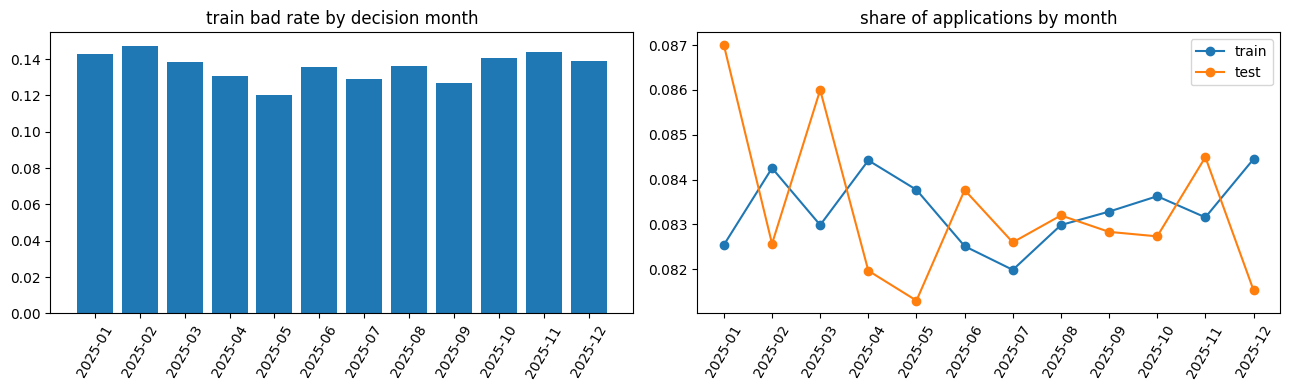

In [9]:
tr_raw, te_raw = T['train_applications'], T['test_applications']
print(f"train bad rate: {tr_raw['target'].mean():.4f}  (n_bad={tr_raw['target'].sum()})")
m = pl.concat([
    tr_raw.select(ym=pl.col('decision_datetime').dt.strftime('%Y-%m'), target='target', split=pl.lit('train')),
    te_raw.select(ym=pl.col('decision_datetime').dt.strftime('%Y-%m'), target=pl.lit(None, pl.Int64), split=pl.lit('test')),
])
tm = m.group_by('ym', 'split').agg(n=pl.len(), rate=pl.col('target').mean()).sort('ym')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
p = tm.filter(pl.col('split') == 'train')
ax[0].bar(p['ym'], p['rate']); ax[0].set_title('train bad rate by decision month'); ax[0].tick_params(axis='x', rotation=60)
for s in ['train', 'test']:
    q = tm.filter(pl.col('split') == s)
    ax[1].plot(q['ym'], q['n'] / q['n'].sum(), marker='o', label=s)
ax[1].legend(); ax[1].set_title('share of applications by month'); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'target_time.png', dpi=90); plt.show()

#### Insights

> The bad rate is 13.6% and stays between 12% and 15% in every month of 2025. Train and test applications are interleaved over the same twelve months in the same 70/30 proportion, so the test set is a random sample of the same period rather than an out-of-time holdout.

> Stratified K-fold therefore mimics the leaderboard split, and no time-based validation is needed.

## Risk-Based Pricing

The interest rate takes only five values. If the lender priced loans from a risk grade, the rate itself carries that grade.

In [10]:
pricing = (tr_raw.group_by('annual_interest_rate')
           .agg(n=pl.len(), bad_rate=pl.col('target').mean()).sort('annual_interest_rate'))
print(pricing)
print('univariate KS of annual_interest_rate:', round(ks_score(tr_raw['target'], tr_raw['annual_interest_rate']), 4))

shape: (5, 3)
┌──────────────────────┬───────┬──────────┐
│ annual_interest_rate ┆ n     ┆ bad_rate │
│ ---                  ┆ ---   ┆ ---      │
│ f64                  ┆ u32   ┆ f64      │
╞══════════════════════╪═══════╪══════════╡
│ 0.16                 ┆ 12560 ┆ 0.054936 │
│ 0.2                  ┆ 29800 ┆ 0.106477 │
│ 0.24                 ┆ 22358 ┆ 0.177655 │
│ 0.28                 ┆ 4938  ┆ 0.303564 │
│ 0.32                 ┆ 344   ┆ 0.502907 │
└──────────────────────┴───────┴──────────┘
univariate KS of annual_interest_rate: 0.2301


#### Insights

> The bad rate rises monotonically from 5.5% at a 16% rate to 50% at a 32% rate, a univariate KS of 0.23. The offline analysis shows that the mean bureau score falls by about 40 points per tier, so the rate is largely a coarse copy of the bureau score. Inside bureau-score deciles the rate keeps only about 0.06 KS.

## Pre-Application Spending Burst

E-commerce orders are counted per customer per week before the decision, separately for bad and good loans. The shape of this curve sets the aggregation windows.

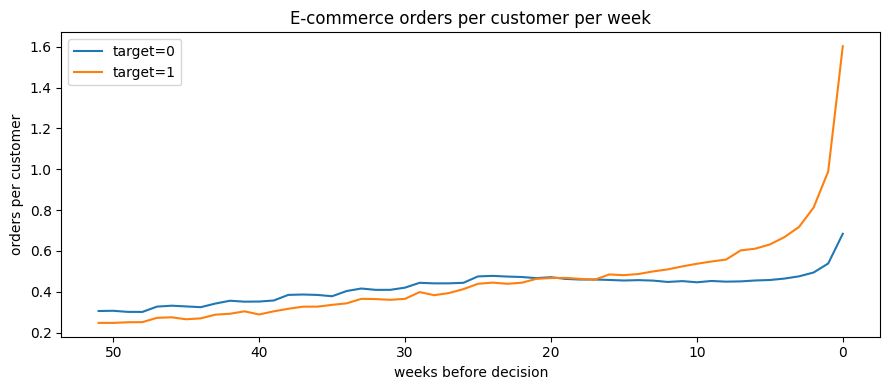

shape: (6, 4)
┌─────┬──────────┬──────────┬───────────────┐
│ wk  ┆ 0        ┆ 1        ┆ bad_over_good │
│ --- ┆ ---      ┆ ---      ┆ ---           │
│ i64 ┆ f64      ┆ f64      ┆ f64           │
╞═════╪══════════╪══════════╪═══════════════╡
│ 0   ┆ 0.684278 ┆ 1.603029 ┆ 2.34266       │
│ 1   ┆ 0.53874  ┆ 0.989376 ┆ 1.836463      │
│ 2   ┆ 0.494652 ┆ 0.81277  ┆ 1.643113      │
│ 3   ┆ 0.47584  ┆ 0.717682 ┆ 1.508241      │
│ 4   ┆ 0.464946 ┆ 0.668034 ┆ 1.436798      │
│ 5   ┆ 0.457871 ┆ 0.63185  ┆ 1.379974      │
└─────┴──────────┴──────────┴───────────────┘


In [11]:
o = (T['ecommerce_transactions'].join(tr_raw.select('customer_id', 'decision_datetime', 'target'), on='customer_id')
     .group_by('order_id').agg(pl.col('customer_id', 'decision_datetime', 'transaction_datetime', 'target').first())
     .with_columns(wk=((pl.col('decision_datetime') - pl.col('transaction_datetime')).dt.total_days() // 7)))
ncls = tr_raw.group_by('target').agg(ncust=pl.len())
wk = (o.filter(pl.col('wk') < 52).group_by('wk', 'target').agg(n=pl.len()).join(ncls, on='target')
      .with_columns(per=pl.col('n') / pl.col('ncust')).sort('wk'))
fig, ax = plt.subplots(figsize=(9, 4))
for k in (0, 1):
    q = wk.filter(pl.col('target') == k)
    ax.plot(q['wk'], q['per'], label=f'target={k}')
ax.invert_xaxis(); ax.set_xlabel('weeks before decision'); ax.set_ylabel('orders per customer'); ax.legend()
ax.set_title('E-commerce orders per customer per week')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'ecom_burst.png', dpi=90); plt.show()
r = wk.pivot(on='target', index='wk', values='per').sort('wk').head(6)
print(r.with_columns(bad_over_good=pl.col('1') / pl.col('0')))

#### Insights

> Bad and good customers order at the same rate until about 16 weeks before the decision. After that, bad customers accelerate and reach 2.3 times the good rate in the final week. Lifetime totals dilute this signal, so the features use 7 to 90 day windows and an acceleration ratio against a 17-52 week baseline.

> Account behaviour shows the same pattern. The outflow-to-inflow ratio and low-balance days of bad customers deteriorate over the last 6 months, although they look slightly healthier than good customers a year earlier. Recent-versus-baseline deltas capture this.

## Lateness Severity

Repayment lateness has two sides: how often a customer is late, and how late the payment is when it is late. Days late among paid-late installments are compared between bad and good customers.

shape: (2, 7)
┌────────┬──────┬──────┬──────┬──────┬───────┬─────────────────────┐
│ target ┆ q10  ┆ q25  ┆ q50  ┆ q75  ┆ q90   ┆ n_late_installments │
│ ---    ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---   ┆ ---                 │
│ i64    ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64   ┆ u32                 │
╞════════╪══════╪══════╪══════╪══════╪═══════╪═════════════════════╡
│ 0      ┆ 30.0 ┆ 30.0 ┆ 31.0 ┆ 61.0 ┆ 91.0  ┆ 216447              │
│ 1      ┆ 30.0 ┆ 31.0 ┆ 61.0 ┆ 92.0 ┆ 123.0 ┆ 65188               │
└────────┴──────┴──────┴──────┴──────┴───────┴─────────────────────┘


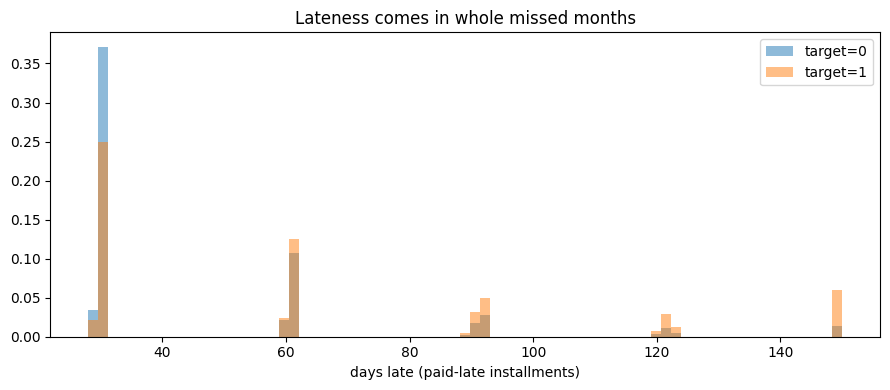

In [12]:
rp = (T['repayment_history'].join(tr_raw.select('customer_id', 'target'), on='customer_id')
      .filter(pl.col('amount_paid') >= pl.col('amount_due'))
      .with_columns(late_d=(pl.col('last_payment_datetime') - pl.col('due_date')).dt.total_days())
      .filter(pl.col('late_d') > 0))
print(rp.group_by('target').agg([pl.col('late_d').quantile(q).alias(f'q{int(q * 100)}') for q in (0.1, 0.25, 0.5, 0.75, 0.9)]
                                + [pl.len().alias('n_late_installments')]).sort('target'))
fig, ax = plt.subplots(figsize=(9, 4))
for k in (0, 1):
    ax.hist(rp.filter(pl.col('target') == k)['late_d'].clip(upper_bound=150), bins=75, density=True, alpha=0.5, label=f'target={k}')
ax.set_xlabel('days late (paid-late installments)'); ax.legend(); ax.set_title('Lateness comes in whole missed months')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'late_severity.png', dpi=90); plt.show()

#### Insights

> Late payments cluster at about 30, 61 and 91 days. A late installment is a skipped month that is settled at a following due date. The median good customer catches up after one month and the median bad customer after two. Severity is therefore a separate measurement from the frequency features of version 1 (Spearman correlation about 0.63). `sv_maxdpd_mean_late` and `sv_share30_of_late` capture it.

> The offline residual analysis of the version 1 predictions also found smaller orthogonal signals: the first installment of each loan, the latest loan, the share of inflows that are not income, the bureau score trend over all pulls, and cancelled and night-time orders before the application. Each one moves the cross-fitted KS of version 1 by only 0.001 to 0.003. They are added together as the version 2 features.

## Price Premium

Spending totals mix three things: how often a customer orders, how many units they buy, and how expensive each unit is. Here the unit price of every item is compared with the typical price of its category on a log scale (z-score of log unit price within the category). The customer's average z is their price premium. This exploratory view uses one pooled reference; the model features use a stricter one, built only from purchases dated before each application's decision month (see the leakage test below).

KS of the customer price premium: 0.3684
shape: (7, 3)
┌──────────────────┬──────────────┬───────────────────┐
│ product_category ┆ sd_log_price ┆ median_unit_price │
│ ---              ┆ ---          ┆ ---               │
│ str              ┆ f64          ┆ f64               │
╞══════════════════╪══════════════╪═══════════════════╡
│ education        ┆ 0.691738     ┆ 99000.0           │
│ electronics      ┆ 0.687655     ┆ 1.159e6           │
│ fashion          ┆ 0.691151     ┆ 168000.0          │
│ groceries        ┆ 0.694808     ┆ 57000.0           │
│ health           ┆ 0.691698     ┆ 115000.0          │
│ home             ┆ 0.68923      ┆ 294000.0          │
│ personal_care    ┆ 0.692607     ┆ 73000.0           │
└──────────────────┴──────────────┴───────────────────┘


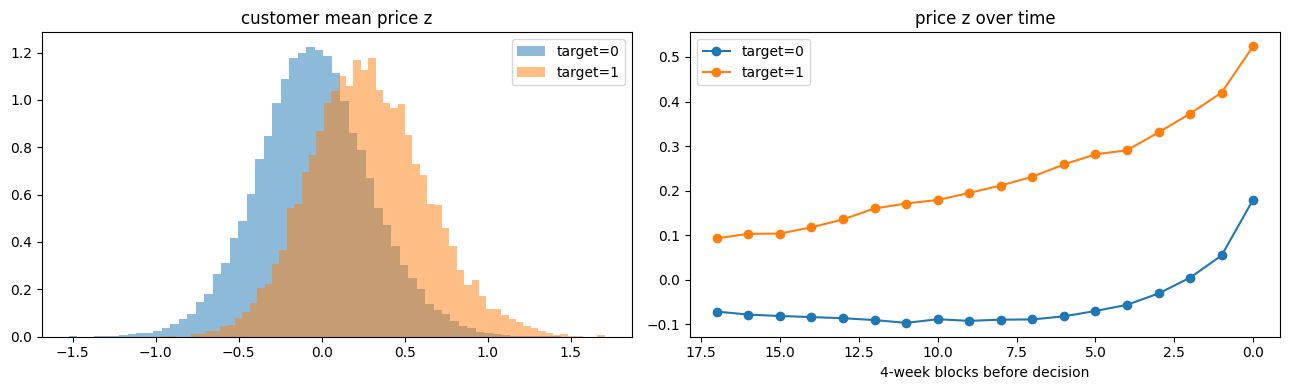

In [13]:
e = (T['ecommerce_transactions'].join(tr_raw.select('customer_id', 'decision_datetime', 'target'), on='customer_id')
     .with_columns(lu=(pl.col('item_total') / pl.col('quantity')).log(),
                   blk=((pl.col('decision_datetime') - pl.col('transaction_datetime')).dt.total_days() // 28)))
e = e.with_columns(z=(pl.col('lu') - pl.col('lu').mean().over('product_category')) / pl.col('lu').std().over('product_category'))
prem = e.group_by('customer_id', 'target').agg(z=pl.col('z').mean())
print('KS of the customer price premium:', round(ks_score(prem['target'], prem['z']), 4))
print(e.group_by('product_category').agg(sd_log_price=pl.col('lu').std(), median_unit_price=(pl.col('lu').median().exp() / 1000).round() * 1000).sort('product_category'))
prof = e.filter(pl.col('blk') < 18).group_by('blk', 'target').agg(z=pl.col('z').mean()).sort('blk')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in (0, 1):
    ax[0].hist(prem.filter(pl.col('target') == k)['z'], bins=60, alpha=0.5, density=True, label=f'target={k}')
    q = prof.filter(pl.col('target') == k)
    ax[1].plot(q['blk'], q['z'], marker='o', label=f'target={k}')
ax[0].set_title('customer mean price z'); ax[0].legend()
ax[1].invert_xaxis(); ax[1].set_xlabel('4-week blocks before decision'); ax[1].set_title('price z over time'); ax[1].legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'price_premium.png', dpi=90); plt.show()

#### Insights

> Bad customers pay more per unit than good customers in every category, and the gap is visible more than a year before the application (about 0.16 standard deviations) and widens to about 0.35 near the decision. The customer price premium alone reaches a KS of about 0.37, above the best repayment feature. Log unit prices have the same spread (sd about 0.69) in all seven categories, so one category-free z-score is meaningful.

> The version 3 model could not see this. Its spending features add up order totals, which mixes unit price with basket size, and the residual analysis showed that version 3 even over-reads basket quantity as risk: the bad rate is flat across quantity levels while the version 3 prediction rises with them. The version 5 features therefore separate unit price (`pp_*`, overall, completed orders, recent and old windows, per category) from quantity per item (`pp_qty_item*`). The decision month is added as well, because the bad rate moves between 12.0% in May and 14.7% in February and the test set covers the same months.

## Table Coverage

Coverage of each auxiliary table is compared between splits, because a coverage mismatch would make the CV score unrepresentative.

In [14]:
split = pl.concat([tr_raw.select('customer_id', split=pl.lit('train')), te_raw.select('customer_id', split=pl.lit('test'))])
cov = []
for t in ['previous_applications', 'repayment_history', 'account_behavior', 'bureau_observations', 'ecommerce_transactions']:
    c = split.with_columns(has=pl.col('customer_id').is_in(T[t]['customer_id'].unique().implode()))
    cov.append(c.group_by('split').agg(pl.col('has').mean()).with_columns(table=pl.lit(t)))
print(pl.concat(cov).pivot(on='split', index='table', values='has'))

shape: (5, 3)
┌────────────────────────┬────────┬────────┐
│ table                  ┆ train  ┆ test   │
│ ---                    ┆ ---    ┆ ---    │
│ str                    ┆ f64    ┆ f64    │
╞════════════════════════╪════════╪════════╡
│ previous_applications  ┆ 0.7    ┆ 0.7    │
│ repayment_history      ┆ 0.6616 ┆ 0.6615 │
│ account_behavior       ┆ 0.7    ┆ 0.7    │
│ bureau_observations    ┆ 1.0    ┆ 1.0    │
│ ecommerce_transactions ┆ 1.0    ┆ 1.0    │
└────────────────────────┴────────┴────────┘


#### Insights

> Bureau and e-commerce data exist for every customer, while previous applications and account data exist for exactly 70% of customers in both splits (66% for repayment). The remaining 30% are thin-file customers, whose bad rate is lower (11.7% versus 14.4%).

> The offline audit also confirms that every auxiliary row is already dated before its customer's `decision_datetime`. There are no exact or near-duplicate customers across splits, and the hashed IDs carry no signal (KS < 0.01). The feature code still filters on the cutoff explicitly and is tested against injected future rows below.

## Offline Audit of Versions 6 to 8

Versions 5 to 8 scored the same within noise (public 0.5615, 0.5612 and about 0.561; held-out blend KS 0.5263 to 0.5277). The table summarises the offline analyses of their out-of-fold predictions (`eda/60` to `eda/96`, plus two independent reviews in `eda/v7_review` and `eda/v8_review`), all run on a laptop CPU without training any model. The version 9 tests use the version 8 blend as the reference score and keep zero and rare values in their own bins: the review found that plain quantile bins merge a dominant zero with its rare positive tail, which hid count features from the earlier screens.

| Question | Result |
|---|---|
| Do historical loans help as extra training rows? (v8) | Paired per model: -0.0026 to +0.0015 OOF KS, every bootstrap interval crosses zero. Their snapshots are not exactly reconstructible and their e-commerce mapping differs. Dropped. |
| Are customers linked (clones, rings, households)? (`eda/90`) | 14 exact-value keys (timestamps, balances, order totals, profiles): a bad linked train customer never changes the observed/expected bad count beyond z = 2. |
| Does any event type in any time window still carry signal? (`eda/91`) | 1,142 score tests of event counts and sums per window against the v8 residual: largest z = 3.81, the expected maximum under noise is 3.8. |
| Hidden terms in arithmetic identities? (`eda/92`) | Utilisation, order totals, installments, due dates, payment days, balance identity and amount grids are exact; the inexact ones (balance path, partial payments, approval ratio) leave chi2/df at most 1.4. |
| Behavioural personas? (`eda/93`) | k-means on 30 composition shares (k = 2 to 20): raw bad rate 10% to 15% across clusters, chi2/df against v8 at most 0.96. |
| Shrinkage or nuisance removal? (`eda/94`, `eda/95`) | Empirical-Bayes lateness, premium, burst and bureau scores, and the premium net of income: univariate KS up to +0.007 but already used by v8 (chi2/df at most 2.1, below the multiple-testing bar). |
| One score scale for all segments? (`eda/96`) | Per-segment recalibration lowers held-out KS by 0.0005 to 0.0026; logit stacking of the saved models raises it by 0.0008 (5 of 6 halves). |
| Why is public about 0.03 above OOF? | Not sampling (subset bias +0.002) and not the test features (test and OOF prediction distributions match, KS distance below 0.007). It is a property of the fixed public subset and cannot be used. |
| Newer tabular foundation models? | TabPFN-3.5, Causilo, EXAONE, LimiX-2 and TabICLv2 were all tried. The two that run on full 56,000-row folds score 0.519 and 0.524, at or below the trees; the other three do not fit a full fold on a T4. |

#### Insights

> The search for unused information is exhausted at the resolution these tests reach (a cross-fitted KS gain of about 0.002). Version 9 therefore spends the run on the model side only, where the gains are known to be small but real.

---

# Feature Engineering <a name="4"></a>

---

Each auxiliary table is aggregated to one row per customer, and every builder filters on the customer's own cutoff (`decision_datetime`). Bureau reports must be *available* before the cutoff, account months must be *complete* before it, and e-commerce `order_total` is de-duplicated per order before it is summed, because it repeats on every item row.

## Feature Builders

The builders cover application and profile affordability ratios, bureau scores per provider and their change since earlier pulls, repayment lateness depth and active obligations, cash-flow levels and recent deltas, e-commerce recency and acceleration, and previous application outcomes and pricing.

In [15]:
DAY = 86400.0


def _days(a, b):
    return (pl.col(a) - pl.col(b)).dt.total_seconds() / DAY


def app_features(apps: pl.DataFrame, prof: pl.DataFrame) -> pl.DataFrame:
    d = apps.join(prof, on="customer_id", how="left")
    return d.select(
        "customer_id",
        "loan_amount", "annual_interest_rate", "proposed_monthly_installment", "loan_purpose",
        "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
        "dependents", "housing_status",
        decision_lag_h=(pl.col("decision_datetime") - pl.col("application_datetime")).dt.total_seconds() / 3600,
        app_hour=pl.col("application_datetime").dt.hour(),
        app_dow=pl.col("application_datetime").dt.weekday(),
        dti_declared=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
        lti_declared=pl.col("loan_amount") / pl.col("declared_monthly_income"),
        tenure_over_age=pl.col("employment_tenure_months") / (pl.col("age") * 12),
        income_per_head=pl.col("declared_monthly_income") / (1 + pl.col("dependents")),
    )


def bureau_features(apps: pl.DataFrame, bureau: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", sel_app=pl.col("application_id"), cutoff=pl.col("decision_datetime"))
    b = bureau.join(cut, on="customer_id").filter(pl.col("available_datetime") <= pl.col("cutoff"))
    b = b.with_columns(
        stale_d=_days("cutoff", "report_datetime"),
        delay_d=_days("available_datetime", "report_datetime"),
        is_sel=pl.col("application_id") == pl.col("sel_app"),
        prov=pl.col("bureau_provider").str.replace("Bureau_", "").str.to_lowercase(),
    )
    cur = b.filter("is_sel")
    num = ["score", "active_accounts", "outstanding_balance", "revolving_credit_limit",
           "revolving_outstanding_balance", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m"]
    agg = cur.group_by("customer_id").agg(
        bc_n_reports=pl.len(),
        bc_n_scored=pl.col("score").is_not_null().sum(),
        bc_score_mean=pl.col("score").mean(), bc_score_min=pl.col("score").min(),
        bc_score_max=pl.col("score").max(), bc_score_std=pl.col("score").std(),
        bc_active_max=pl.col("active_accounts").max(),
        bc_outstanding_max=pl.col("outstanding_balance").max(),
        bc_revlimit_max=pl.col("revolving_credit_limit").max(),
        bc_revbal_max=pl.col("revolving_outstanding_balance").max(),
        bc_util_max=pl.col("utilization").max(), bc_util_mean=pl.col("utilization").mean(),
        bc_inq_max=pl.col("inquiries_last_6m").max(), bc_inq_mean=pl.col("inquiries_last_6m").mean(),
        bc_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bc_delinq_sum=pl.col("delinquent_accounts_last_12m").sum(),
        bc_stale_mean=pl.col("stale_d").mean(), bc_stale_max=pl.col("stale_d").max(),
        bc_delay_mean=pl.col("delay_d").mean(),
    )
    piv = cur.pivot(on="prov", index="customer_id", values=["score", "utilization", "inquiries_last_6m",
                                                            "delinquent_accounts_last_12m", "outstanding_balance"],
                    aggregate_function="first")
    piv = piv.rename({c: "bp_" + c.replace("inquiries_last_6m", "inq").replace("delinquent_accounts_last_12m", "delinq")
                      .replace("outstanding_balance", "out").replace("utilization", "util")
                      for c in piv.columns if c != "customer_id"})
    # history: bureau pulled at earlier (previous) applications
    hist = b.filter(~pl.col("is_sel")).group_by("customer_id").agg(
        bh_n_pulls=pl.col("application_id").n_unique(),
        bh_score_mean=pl.col("score").mean(), bh_score_min=pl.col("score").min(),
        bh_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bh_inq_mean=pl.col("inquiries_last_6m").mean(),
        bh_last_score=pl.col("score").sort_by("report_datetime", "bureau_observation_id").drop_nulls().last(),
        bh_last_outstanding=pl.col("outstanding_balance").sort_by("report_datetime", "bureau_observation_id").last(),
        bh_pulls_180d=pl.col("application_id").filter(pl.col("stale_d") <= 180).n_unique(),
    )
    out = agg.join(piv, on="customer_id", how="left").join(hist, on="customer_id", how="left")
    return out.with_columns(
        bh_score_delta=pl.col("bc_score_mean") - pl.col("bh_last_score"),
        bh_outstanding_delta=pl.col("bc_outstanding_max") - pl.col("bh_last_outstanding"),
    )


def repayment_features(apps: pl.DataFrame, rep: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    r = rep.join(cut, on="customer_id").filter(pl.col("due_date") <= pl.col("cutoff"))
    r = r.with_columns(
        age_d=_days("cutoff", "due_date"),
        unpaid=pl.col("amount_due") - pl.col("amount_paid"),
        late_d=pl.when(pl.col("amount_paid") >= pl.col("amount_due")).then(_days("last_payment_datetime", "due_date")),
    )
    w = lambda days: pl.col("age_d") <= days  # noqa: E731
    agg = r.group_by("customer_id").agg(
        rp_n_loans=pl.col("loan_id").n_unique(), rp_n_inst=pl.len(),
        rp_maxdpd_max=pl.col("max_days_past_due").max(), rp_maxdpd_mean=pl.col("max_days_past_due").mean(),
        rp_n_dpd1=(pl.col("max_days_past_due") > 0).sum(), rp_n_dpd30=(pl.col("max_days_past_due") >= 30).sum(),
        rp_n_dpd60=(pl.col("max_days_past_due") >= 60).sum(), rp_n_dpd90=(pl.col("max_days_past_due") >= 90).sum(),
        rp_frac_dpd1=(pl.col("max_days_past_due") > 0).mean(), rp_frac_dpd30=(pl.col("max_days_past_due") >= 30).mean(),
        rp_cur_dpd_max=pl.col("days_past_due").max(), rp_n_unpaid=(pl.col("unpaid") > 0).sum(),
        rp_unpaid_amt=pl.col("unpaid").sum(),
        rp_paid_ratio=pl.col("amount_paid").sum() / pl.col("amount_due").sum(),
        rp_late_mean=pl.col("late_d").mean(), rp_late_max=pl.col("late_d").max(),
        rp_maxdpd_6m=pl.col("max_days_past_due").filter(w(183)).max(),
        rp_maxdpd_12m=pl.col("max_days_past_due").filter(w(365)).max(),
        rp_frac_dpd1_6m=(pl.col("max_days_past_due") > 0).filter(w(183)).mean(),
        rp_late_mean_6m=pl.col("late_d").filter(w(183)).mean(),
        rp_maxdpd_last3=pl.col("max_days_past_due").sort_by("due_date", "loan_id").tail(3).max(),
        rp_days_since_delinq=pl.col("age_d").filter(pl.col("max_days_past_due") > 0).min(),
        rp_days_since_due=pl.col("age_d").min(),
    )
    # active loans: fewer installments observed than contracted term -> remaining obligation
    loans = r.group_by("loan_id").agg(customer_id=pl.col("customer_id").first(), n_seen=pl.len(),
                                      inst=pl.col("amount_due").first())
    loans = loans.join(prev.select("loan_id", "term_months"), on="loan_id", how="left").with_columns(
        remaining=(pl.col("term_months") - pl.col("n_seen")).clip(lower_bound=0))
    act = loans.group_by("customer_id").agg(
        rp_n_active=(pl.col("remaining") > 0).sum(),
        rp_active_inst=pl.col("inst").filter(pl.col("remaining") > 0).sum(),
        rp_remaining_oblig=(pl.col("remaining") * pl.col("inst")).sum(),
    )
    return agg.join(act, on="customer_id", how="left")


def account_features(apps: pl.DataFrame, acc: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    a = acc.join(cut, on="customer_id").filter(
        pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).sort("customer_id", "month")
    a = a.with_columns(mago=pl.col("month").rank("dense", descending=True).over("customer_id"))
    l3 = pl.col("mago") <= 3
    out = a.group_by("customer_id").agg(
        ac_n_months=pl.len(),
        ac_inflow_mean=pl.col("inflows").mean(), ac_outflow_mean=pl.col("outflows").mean(),
        ac_income_mean=pl.col("income_like_credits").mean(), ac_income_std=pl.col("income_like_credits").std(),
        ac_income_min=pl.col("income_like_credits").min(),
        ac_avgbal_mean=pl.col("average_balance").mean(), ac_minbal_min=pl.col("minimum_balance").min(),
        ac_minbal_mean=pl.col("minimum_balance").mean(),
        ac_lowdays_mean=pl.col("low_balance_days").mean(), ac_lowdays_max=pl.col("low_balance_days").max(),
        ac_frac_zero_min=(pl.col("minimum_balance") == 0).mean(),
        ac_net_flow_mean=(pl.col("inflows") - pl.col("outflows")).mean(),
        ac_out_in_ratio=pl.col("outflows").sum() / pl.col("inflows").sum(),
        ac_income_l3=pl.col("income_like_credits").filter(l3).mean(),
        ac_avgbal_l3=pl.col("average_balance").filter(l3).mean(),
        ac_lowdays_l3=pl.col("low_balance_days").filter(l3).mean(),
        ac_out_in_l3=pl.col("outflows").filter(l3).sum() / pl.col("inflows").filter(l3).sum(),
        ac_last_close=pl.col("closing_balance").last(),
        ac_out_in_b=pl.col("outflows").filter(pl.col("mago").is_between(7, 12)).sum()
        / pl.col("inflows").filter(pl.col("mago").is_between(7, 12)).sum(),
        ac_lowdays_b=pl.col("low_balance_days").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_avgbal_b=pl.col("average_balance").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_out_in_l1=(pl.col("outflows") / pl.col("inflows")).filter(pl.col("mago") == 1).first(),
        ac_close_slope=pl.cov(pl.col("mago").cast(pl.Float64), pl.col("closing_balance").cast(pl.Float64))
        / pl.col("mago").cast(pl.Float64).var() * -1,
    )
    return out.with_columns(
        ac_income_cv=pl.col("ac_income_std") / pl.col("ac_income_mean"),
        ac_income_trend=pl.col("ac_income_l3") / pl.col("ac_income_mean"),
        ac_bal_trend=pl.col("ac_avgbal_l3") / (pl.col("ac_avgbal_mean") + 1),
        ac_out_in_delta=pl.col("ac_out_in_l3") - pl.col("ac_out_in_b"),
        ac_lowdays_delta=pl.col("ac_lowdays_l3") - pl.col("ac_lowdays_b"),
        ac_bal_delta=(pl.col("ac_avgbal_l3") + 1) / (pl.col("ac_avgbal_b") + 1),
    )


def ecommerce_features(apps: pl.DataFrame, ec: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    e = ec.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed")
    # order level: order_total repeats on each item -> dedupe before aggregating
    o = e.group_by("order_id").agg(pl.col("customer_id", "age_d", "order_total", "payment_method", "done").first())
    agg = o.group_by("customer_id").agg(
        ec_n_orders=pl.len(), ec_cancel_rate=1 - pl.col("done").mean(),
        ec_spend=pl.col("order_total").filter("done").sum(),
        ec_aov=pl.col("order_total").filter("done").mean(),
        ec_recency_d=pl.col("age_d").min(), ec_tenure_d=pl.col("age_d").max(),
        ec_orders_7d=(pl.col("age_d") <= 7).sum(), ec_orders_14d=(pl.col("age_d") <= 14).sum(),
        ec_orders_30d=(pl.col("age_d") <= 30).sum(), ec_orders_60d=(pl.col("age_d") <= 60).sum(),
        ec_orders_90d=(pl.col("age_d") <= 90).sum(),
        ec_base_wk=((pl.col("age_d") > 120) & (pl.col("age_d") <= 365)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=365) - 120).clip(lower_bound=7) / 7),
        ec_spend_30d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 30)).sum(),
        ec_spend_90d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 90)).sum(),
        ec_cancel_90d=(~pl.col("done")).filter(pl.col("age_d") <= 90).sum(),
        **{f"ec_pm_{m}": (pl.col("payment_method") == m).mean()
           for m in ["COD", "e_wallet", "bank_transfer", "debit_card", "credit_card"]},
    )
    cat = (e.filter("done").group_by("customer_id", "product_category").agg(s=pl.col("item_total").sum())
           .with_columns(s=pl.col("s") / pl.col("s").sum().over("customer_id"))
           .pivot(on="product_category", index="customer_id", values="s"))
    cat = cat.rename({c: f"ec_cat_{c}" for c in cat.columns if c != "customer_id"})
    out = agg.join(cat, on="customer_id", how="left").with_columns(
        ec_spend_per_month=pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1),
        ec_spend_90d_ratio=pl.col("ec_spend_90d") / 3 / (pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1) + 1),
    )
    return out.with_columns(
        pl.col("^ec_cat_.*$").fill_null(0),
        ec_accel_30d=(pl.col("ec_orders_30d") / (30 / 7)) / (pl.col("ec_base_wk") + 0.1),
        ec_accel_90d=(pl.col("ec_orders_90d") / (90 / 7)) / (pl.col("ec_base_wk") + 0.1),
    )


def prev_features(apps: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), cur_rate=pl.col("annual_interest_rate"),
                      cur_amt=pl.col("loan_amount"))
    p = prev.join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    p = p.with_columns(age_d=_days("cutoff", "application_datetime"))
    out = p.group_by("customer_id").agg(
        pv_n=pl.len(), pv_n_appr=(pl.col("decision") == "approved").sum(),
        pv_n_rej=(pl.col("decision") == "rejected").sum(), pv_n_canc=(pl.col("decision") == "cancelled").sum(),
        pv_rej_rate=(pl.col("decision") == "rejected").mean(),
        pv_days_since_last=pl.col("age_d").min(), pv_days_since_first=pl.col("age_d").max(),
        pv_n_90d=(pl.col("age_d") <= 90).sum(), pv_n_180d=(pl.col("age_d") <= 180).sum(),
        pv_rej_365d=((pl.col("decision") == "rejected") & (pl.col("age_d") <= 365)).sum(),
        pv_rate_mean=pl.col("annual_interest_rate").mean(), pv_rate_max=pl.col("annual_interest_rate").max(),
        pv_rate_last=pl.col("annual_interest_rate").sort_by("application_datetime", "application_id").drop_nulls().last(),
        pv_appr_ratio=(pl.col("approved_amount") / pl.col("requested_amount")).mean(),
        pv_req_mean=pl.col("requested_amount").mean(), pv_appr_sum=pl.col("approved_amount").sum(),
        pv_appr_max=pl.col("approved_amount").max(),
        pv_last_decision_rej=(pl.col("decision").sort_by("application_datetime", "application_id").last() == "rejected"),
        cur_rate=pl.col("cur_rate").first(), cur_amt=pl.col("cur_amt").first(),
    )
    return out.with_columns(
        pv_rate_delta=pl.col("cur_rate") - pl.col("pv_rate_last"),
        pv_amt_vs_max=pl.col("cur_amt") / pl.col("pv_appr_max"),
        pv_last_decision_rej=pl.col("pv_last_decision_rej").cast(pl.Int8),
    ).drop("cur_rate", "cur_amt")


def v2_features(apps: pl.DataFrame, tables: dict) -> pl.DataFrame:
    cut = apps.select("customer_id", "application_id", cutoff=pl.col("decision_datetime"),
                      inst_new=pl.col("proposed_monthly_installment"), amt_new=pl.col("loan_amount"))
    # bureau: score trend/range over every pull, newest report, delinquency over all pulls, external inquiries
    b = tables["bureau_observations"].join(cut.select("customer_id", "cutoff", sel=pl.col("application_id")), on="customer_id")
    b = b.filter(pl.col("available_datetime") <= pl.col("cutoff")).with_columns(
        age_d=_days("cutoff", "report_datetime"), is_sel=pl.col("application_id") == pl.col("sel"))
    bz = b.group_by("customer_id").agg(
        bz_trend=pl.cov(pl.col("age_d"), pl.col("score")) / pl.col("age_d").var() * -365,
        bz_range=pl.col("score").max() - pl.col("score").min(),
        bz_newest=pl.col("score").sort_by("report_datetime", "bureau_observation_id").drop_nulls().last(),
        bz_delinq_all_mean=pl.col("delinquent_accounts_last_12m").mean(),
        bz_active_trend=pl.col("active_accounts").filter("is_sel").mean()
        - pl.col("active_accounts").filter(~pl.col("is_sel")).mean(),
        bz_inq_cur=pl.col("inquiries_last_6m").filter("is_sel").mean(),
    )
    p = tables["previous_applications"].join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    own6 = p.filter(_days("cutoff", "application_datetime") <= 183).group_by("customer_id").agg(own6=pl.len())
    bz = bz.join(own6, on="customer_id", how="left").with_columns(
        bz_inq_external=pl.col("bz_inq_cur") - pl.col("own6").fill_null(0)).drop("bz_inq_cur", "own6")
    # previous approvals: tenor mix, recency, recent approved volume, remaining scheduled obligation
    ap = p.filter(pl.col("decision") == "approved").with_columns(
        age_d=_days("cutoff", "decision_datetime"),
        rem=(pl.col("term_months") - (_days("cutoff", "decision_datetime") / 30.44).floor()).clip(lower_bound=0))
    ob = ap.group_by("customer_id").agg(
        ob_term_mean=pl.col("term_months").mean(), ob_days_since_appr=pl.col("age_d").min(),
        ob_amt_90d=pl.col("approved_amount").filter(pl.col("age_d") <= 90).sum(),
        ob_remaining=(pl.col("scheduled_monthly_installment") * pl.col("rem")).sum(),
        amt_new=pl.col("amt_new").first(),
    ).with_columns(ob_amt_vs_last=pl.col("amt_new") / (pl.col("ob_amt_90d") + 1e6)).drop("amt_new")
    # repayment: first installment, latest loan, 1-29 dpd share, recent trend, streaks, severity when late
    r = tables["repayment_history"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    # loan_id breaks due_date ties between concurrent loans -> deterministic order
    r = r.filter(pl.col("due_date") <= pl.col("cutoff")).sort("customer_id", "due_date", "loan_id").with_columns(
        late=(pl.col("max_days_past_due") > 0).cast(pl.Int32),
        paid=pl.col("amount_paid") >= pl.col("amount_due"),
        late_d=_days("last_payment_datetime", "due_date"),
        k=pl.col("due_date").rank("ordinal").over("loan_id"),
        loan_start=pl.col("due_date").min().over("loan_id"))
    # streak of consecutive late installments within one loan (concurrent loans interleave in time)
    r = r.with_columns(run=(pl.col("late") != pl.col("late").shift(1)).fill_null(True).cum_sum().over("loan_id"))
    streak = (r.filter(pl.col("late") == 1).group_by("customer_id", "loan_id", "run").agg(n=pl.len())
              .group_by("customer_id").agg(rq_streak_max=pl.col("n").max()))
    last = (r.filter(pl.col("loan_start") == pl.col("loan_start").max().over("customer_id"))
            .group_by("customer_id").agg(rq_lastloan_late=pl.col("late").mean(), rq_lastloan_maxdpd=pl.col("max_days_past_due").max()))
    dpd, late = pl.col("max_days_past_due"), pl.col("max_days_past_due") > 0
    rq = r.group_by("customer_id").agg(
        rq_first_inst_late=pl.col("late").filter(pl.col("k") == 1).mean(),
        rq_frac_1_29=(late & (dpd < 30)).mean(),
        rq_late_trend=pl.col("late").tail(6).mean() - pl.col("late").head(pl.len() - 6).mean(),
        sv_maxdpd_mean_late=dpd.filter(late).mean(),
        sv_late_d_mean=pl.col("late_d").filter(pl.col("paid") & (pl.col("late_d") > 0)).mean(),
        sv_share30_of_late=(dpd >= 30).sum() / late.sum(),
        sv_unpaid_of_late=(~pl.col("paid") & late).sum() / late.sum(),
    ).join(streak, on="customer_id", how="left").join(last, on="customer_id", how="left")
    # account: non-income inflows, recent outflows, worst free cash flow, new installment vs free cash / min balance
    a = tables["account_behavior"].join(cut.select("customer_id", "cutoff", "inst_new"), on="customer_id")
    a = a.filter(pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).with_columns(
        l3=pl.col("month").rank("dense", descending=True).over("customer_id") <= 3,
        free=pl.col("inflows") - pl.col("outflows"))
    cf = a.group_by("customer_id").agg(
        cf_nonincome_share=1 - pl.col("income_like_credits").sum() / pl.col("inflows").sum(),
        cf_nonincome_l3=1 - pl.col("income_like_credits").filter("l3").sum() / pl.col("inflows").filter("l3").sum(),
        cf_out_l3=pl.col("outflows").filter("l3").mean(), cf_free_min=pl.col("free").min(),
        cf_free_l3=pl.col("free").filter("l3").mean(), cf_inc_l3=pl.col("income_like_credits").filter("l3").mean(),
        cf_minbal_l3=pl.col("minimum_balance").filter("l3").min(), inst_new=pl.col("inst_new").first(),
    ).with_columns(
        cf_inst_to_free=pl.col("inst_new") / (pl.col("cf_free_l3").clip(lower_bound=0) + 1e5),
        cf_out_to_inc_l3=pl.col("cf_out_l3") / (pl.col("cf_inc_l3") + 1e5),
        cf_inst_to_minbal=pl.col("inst_new") / (pl.col("cf_minbal_l3") + 1e5),
    ).drop("inst_new", "cf_free_l3", "cf_inc_l3")
    # e-commerce: cancellations, night share, basket size, AOV shift, tightest gap, smooth recency-weighted counts
    e = tables["ecommerce_transactions"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    e = e.filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    o = e.group_by("order_id").agg(pl.col("customer_id", "cutoff", "transaction_datetime", "order_total", "order_status").first(),
                                   n_items=pl.len())
    o = o.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       night=pl.col("transaction_datetime").dt.hour() < 5)
    r28, old = pl.col("age_d") <= 28, pl.col("age_d") > 182
    ec = o.group_by("customer_id").agg(
        ec2_base=(old & (pl.col("age_d") <= 730)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=730) - 182).clip(lower_bound=14) / 7),
        ec2_cancel_28=(~pl.col("done")).filter(r28).sum(),
        ec2_night_share_90=pl.col("night").filter(pl.col("age_d") <= 90).mean(),
        ec2_items_per_order_28=pl.col("n_items").filter(r28).mean(),
        ec2_aov_28=pl.col("order_total").filter(pl.col("done") & r28).mean(),
        ec2_aov_old=pl.col("order_total").filter(pl.col("done") & old).mean(),
        ec2_gap_min_28=pl.col("age_d").filter(r28).sort().diff().min(),
        **{f"ec2_ewm{t}": (-pl.col("age_d") / t).exp().sum() for t in (7, 28, 56)},
    ).with_columns(
        ec2_aov_shift=pl.col("ec2_aov_28") / pl.col("ec2_aov_old"),
        ec2_ewm7_rel=pl.col("ec2_ewm7") / (pl.col("ec2_base") + 0.05),
        ec2_ewm28_exc=pl.col("ec2_ewm28") - pl.col("ec2_base") * 4,
        ec2_ewm56_rel=pl.col("ec2_ewm56") / (pl.col("ec2_base") * 8 + 0.05),
    ).drop("ec2_aov_28", "ec2_aov_old", "ec2_ewm7", "ec2_ewm28", "ec2_ewm56")
    out = cut.select("customer_id")
    for part in (bz, ob, rq, cf, ec):
        out = out.join(part, on="customer_id", how="left")
    return out


PP_CATS = ["groceries", "fashion", "electronics", "home", "health", "education", "personal_care"]


def v5_features(apps: pl.DataFrame, tables: dict) -> pl.DataFrame:
    """v5 additions (eda/40-45): unit-price premium within category, basket quantity, decision month.
    Category reference (mean and sd of log unit price, eda/50): an expanding window over item rows of all customers
    (no labels) dated before the first day of the application's decision month, so every application is normalised
    only with prices that were already observed when it was decided."""
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), dm=pl.col("decision_datetime").dt.truncate("1mo"))
    raw = tables["ecommerce_transactions"].with_columns(lu=(pl.col("item_total") / pl.col("quantity")).log(),
                                                        ym=pl.col("transaction_datetime").dt.truncate("1mo"))
    ms = raw.group_by("product_category", "ym").agg(n=pl.len(), s=pl.col("lu").sum(), ss=(pl.col("lu") ** 2).sum())
    ref = (cut.select("dm").unique().join(ms, how="cross").filter(pl.col("ym") < pl.col("dm"))
           .group_by("product_category", "dm").agg(pl.col("n", "s", "ss").sum())
           .with_columns(mu=pl.col("s") / pl.col("n"),
                         sd=((pl.col("ss") - pl.col("s") ** 2 / pl.col("n")) / (pl.col("n") - 1)).sqrt()))
    e = raw.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.join(ref.select("product_category", "dm", "mu", "sd"), on=["product_category", "dm"], how="left")
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       z=(pl.col("lu") - pl.col("mu")) / pl.col("sd"))
    lo, hi = pl.col("z").quantile(0.1), pl.col("z").quantile(0.9)
    pp = e.group_by("customer_id").agg(
        pp_mean=pl.col("z").mean(),
        pp_trim=pl.col("z").filter((pl.col("z") > lo) & (pl.col("z") < hi)).mean(),
        pp_done=pl.col("z").filter("done").mean(), pp_min=pl.col("z").min(), pp_max=pl.col("z").max(),
        pp_30=pl.col("z").filter(pl.col("age_d") <= 30).mean(), pp_90=pl.col("z").filter(pl.col("age_d") <= 90).mean(),
        pp_old=pl.col("z").filter(pl.col("age_d") > 182).mean(),
        pp_qty_item=pl.col("quantity").mean(), pp_qty_item_90=pl.col("quantity").filter(pl.col("age_d") <= 90).mean(),
        **{f"pp_cat_{c}": pl.col("z").filter(pl.col("product_category") == c).mean() for c in PP_CATS},
    )
    month = apps.select("customer_id", dec_month=pl.col("decision_datetime").dt.month())
    return month.join(pp, on="customer_id", how="left")


def build_all(tables: dict) -> pl.DataFrame:
    tr = tables["train_applications"].with_columns(is_train=pl.lit(1))
    te = tables["test_applications"].with_columns(target=pl.lit(None, pl.Int64), is_train=pl.lit(0))
    apps = pl.concat([tr, te], how="diagonal_relaxed")
    f = apps.select("application_id", "customer_id", "decision_datetime", "target", "is_train")
    for part in [
        app_features(apps, tables["customer_profiles"]),
        bureau_features(apps, tables["bureau_observations"]),
        repayment_features(apps, tables["repayment_history"], tables["previous_applications"]),
        account_features(apps, tables["account_behavior"]),
        ecommerce_features(apps, tables["ecommerce_transactions"]),
        prev_features(apps, tables["previous_applications"]),
        v2_features(apps, tables),
        v5_features(apps, tables),
    ]:
        f = f.join(part, on="customer_id", how="left")
    # cross-table ratios: the real affordability picture
    f = f.with_columns(
        has_history=pl.col("pv_n").is_not_null().cast(pl.Int8),
        dti_verified=pl.col("proposed_monthly_installment") / pl.col("ac_income_mean"),
        dti_total=(pl.col("proposed_monthly_installment") + pl.col("rp_active_inst").fill_null(0))
        / pl.col("declared_monthly_income"),
        income_verif_ratio=pl.col("ac_income_mean") / pl.col("declared_monthly_income"),
        debt_to_income=pl.col("bc_outstanding_max") / pl.col("declared_monthly_income"),
        inst_to_avgbal=pl.col("proposed_monthly_installment") / (pl.col("ac_avgbal_mean") + 1),
        ecspend_to_income=pl.col("ec_spend_per_month") / pl.col("declared_monthly_income"),
    )
    return f

In [16]:
t0 = time.time()
feats = build_all(T)
assert feats['application_id'].n_unique() == feats.height == T['train_applications'].height + T['test_applications'].height
print(f'feature matrix {feats.shape} built in {time.time() - t0:.1f}s')

feature matrix (100000, 237) built in 13.2s


## Leakage Injection Test

Fake rows dated after each customer's cutoff are appended to all five dated tables, using extreme values: a DPD of 999, a cancelled 1e9 order, a score of 300 with 99 inquiries, the incomplete decision month with zero income, and an approved 1e9 loan decided after the cutoff. The comparison allows a 1e-9 relative tolerance, because sums of floats can differ in the last bits when the row order changes.

The price reference needs a precise rule. A purchase made after customer A's cutoff is in the past for a customer deciding in a later month, so it may legitimately enter that customer's category reference. The test therefore has two parts. First, rows after the cutoffs of 2,000 random customers must not move any non-price feature of anyone. Second, rows after the cutoffs of 2,000 December customers (which are in nobody's past) must not move any feature at all, which checks the price features' own cutoff as well.

In [17]:
apps_all = pl.concat([T['train_applications'], T['test_applications']], how='diagonal_relaxed').select('customer_id', cut='decision_datetime')
def first_rows(t):
    return T[t].join(fut, on='customer_id').group_by('customer_id').first()
def moved(ref, leak, cols):
    ref, leak = ref.sort('application_id'), leak.sort('application_id')
    return [c for c in cols if not np.allclose(ref[c].cast(pl.Float64).fill_nan(None).fill_null(-7.0).to_numpy(),
                                               leak[c].cast(pl.Float64).fill_nan(None).fill_null(-7.0).to_numpy(), rtol=1e-9, atol=1e-9)]
num_cols = [c for c, d in feats.schema.items() if d.is_numeric()]
fut = apps_all.sample(2000, seed=1)
after = pl.col('cut') + pl.duration(days=5)
inj = {
    'repayment_history': first_rows('repayment_history').with_columns(
        due_date=after, max_days_past_due=pl.lit(999), days_past_due=pl.lit(999)),
    'ecommerce_transactions': first_rows('ecommerce_transactions').with_columns(
        transaction_datetime=pl.col('cut') + pl.duration(hours=1), order_id=pl.lit('O_FAKE') + pl.col('customer_id'),
        order_total=pl.lit(10**9), order_status=pl.lit('cancelled')),
    'bureau_observations': first_rows('bureau_observations').with_columns(
        available_datetime=after, score=pl.lit(300.0), inquiries_last_6m=pl.lit(99)),
    'account_behavior': first_rows('account_behavior').with_columns(
        month=pl.col('cut').dt.truncate('1mo').cast(pl.Date), outflows=pl.lit(10**10), income_like_credits=pl.lit(0)),
    'previous_applications': first_rows('previous_applications').with_columns(
        application_datetime=pl.col('cut') - pl.duration(hours=1), decision_datetime=after, decision=pl.lit('approved'),
        approved_amount=pl.lit(10**9), term_months=pl.lit(6),
        application_id=pl.lit('A_FAKE') + pl.col('customer_id'), loan_id=pl.lit('L_FAKE') + pl.col('customer_id')),
}
T_leak = dict(T)
for t, extra in inj.items():
    T_leak[t] = pl.concat([T[t], extra.select(T[t].columns)], how='vertical_relaxed')
changed = moved(feats, build_all(T_leak), [c for c in num_cols if not c.startswith('pp_')])
assert not changed, f'cutoff leak: {changed}'
print(f'part 1 passed: no non-price feature of any customer moved ({len(num_cols)} numeric features checked)')
fut = apps_all.filter(pl.col('cut').dt.month() == 12).sample(2000, seed=2)
ec = first_rows('ecommerce_transactions').with_columns(
    transaction_datetime=pl.col('cut') + pl.duration(hours=1), order_id=pl.lit('O_FAKE') + pl.col('customer_id'),
    item_total=pl.lit(10**9), quantity=pl.lit(1), product_category=pl.lit('groceries'))
T_leak = dict(T)
T_leak['ecommerce_transactions'] = pl.concat([T['ecommerce_transactions'], ec.select(T['ecommerce_transactions'].columns)], how='vertical_relaxed')
changed = moved(feats, build_all(T_leak), num_cols)
assert not changed, f'cutoff leak (December test): {changed}'
print('part 2 passed: rows after December cutoffs moved no feature, including the price premium')
del T_leak
_ = gc.collect()

part 1 passed: no non-price feature of any customer moved (230 numeric features checked)
part 2 passed: rows after December cutoffs moved no feature, including the price premium


## Feature Diagnostics

Every numeric feature is scored by univariate KS against the target and by PSI between train and test. A high-KS feature that also drifts would split public and private scores, so both are checked together.

In [18]:
ID_COLS  = ['application_id', 'customer_id', 'decision_datetime', 'target', 'is_train']
CAT_COLS = ['loan_purpose', 'region', 'employment_type', 'housing_status']
FEATURES = sorted(c for c in feats.columns if c not in ID_COLS)
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

tr_f, te_f = feats.filter(pl.col('is_train') == 1), feats.filter(pl.col('is_train') == 0)
y = tr_f['target'].to_numpy()
diag = pl.DataFrame({
    'feature': NUM_COLS,
    'ks': [ks_nan(y, tr_f[c].cast(pl.Float64).to_numpy()) for c in NUM_COLS],
    'psi': [psi(tr_f[c].cast(pl.Float64).to_numpy(), te_f[c].cast(pl.Float64).to_numpy()) for c in NUM_COLS],
    'coverage': [1 - tr_f[c].null_count() / tr_f.height for c in NUM_COLS],
}).sort('ks', descending=True)
V2_PREFIX = ('bz_', 'ob_', 'rq_', 'sv_', 'cf_', 'ec2_')
V5_PREFIX = ('pp_', 'dec_month')
V2_FEATURES = [c for c in FEATURES if c.startswith(V2_PREFIX)]
V5_FEATURES = [c for c in FEATURES if c.startswith(V5_PREFIX)]
V3_FEATURES = [c for c in FEATURES if not c.startswith(V5_PREFIX)]
with pl.Config(tbl_rows=25, float_precision=4):
    print(diag.head(25))
    print('version 2 features:')
    print('version 5 features:')
    print(diag.filter(pl.col('feature').is_in(V5_FEATURES)))
print('max PSI over all features:', round(diag['psi'].max(), 5))
print(f'{len(FEATURES)} features ({len(CAT_COLS)} categorical), {len(V5_FEATURES)} new in version 5')

shape: (25, 4)
┌──────────────────┬────────┬────────┬──────────┐
│ feature          ┆ ks     ┆ psi    ┆ coverage │
│ ---              ┆ ---    ┆ ---    ┆ ---      │
│ str              ┆ f64    ┆ f64    ┆ f64      │
╞══════════════════╪════════╪════════╪══════════╡
│ pp_mean          ┆ 0.3689 ┆ 0.0002 ┆ 1.0000   │
│ pp_trim          ┆ 0.3665 ┆ 0.0005 ┆ 1.0000   │
│ pp_done          ┆ 0.3660 ┆ 0.0002 ┆ 1.0000   │
│ pp_90            ┆ 0.3281 ┆ 0.0007 ┆ 0.9555   │
│ rp_frac_dpd1     ┆ 0.3183 ┆ 0.0002 ┆ 0.6616   │
│ pp_30            ┆ 0.3147 ┆ 0.0007 ┆ 0.7430   │
│ ec2_ewm28_exc    ┆ 0.3099 ┆ 0.0006 ┆ 1.0000   │
│ ec_accel_30d     ┆ 0.3090 ┆ 0.0002 ┆ 1.0000   │
│ rp_maxdpd_mean   ┆ 0.3086 ┆ 0.0001 ┆ 0.6616   │
│ ec2_ewm56_rel    ┆ 0.3084 ┆ 0.0003 ┆ 1.0000   │
│ rp_frac_dpd30    ┆ 0.3060 ┆ 0.0006 ┆ 0.6616   │
│ ec2_ewm7_rel     ┆ 0.3041 ┆ 0.0004 ┆ 1.0000   │
│ ec_accel_90d     ┆ 0.3019 ┆ 0.0007 ┆ 1.0000   │
│ rp_late_mean     ┆ 0.2982 ┆ 0.0001 ┆ 0.6596   │
│ ec_spend_30d     ┆ 0.2912 ┆ 0.000

#### Insights

> The strongest single features are repayment lateness (`rp_frac_dpd1`, KS about 0.32), e-commerce acceleration (`ec_accel_30d`, about 0.31) and the mean bureau score (about 0.25). The first two are nearly orthogonal to the bureau score and keep about 0.30 KS inside score deciles, which is why combining sources gives a large lift. A rank average of nine such features with no training already reaches a KS of about 0.41.

> The version 2 features have univariate KS up to about 0.27, but they were chosen for what they add on top of version 1, not for their stand-alone KS. The maximum PSI is far below the usual 0.1 alert level, so no feature needs to be dropped for stability.

## Additivity of Risk Signals

The bad rate is tabulated over quintiles of two signal families, with missing values as a sixth bin. If the lines are parallel on the log-odds scale, the families add up and deep interactions are not needed, which favours shallow trees.

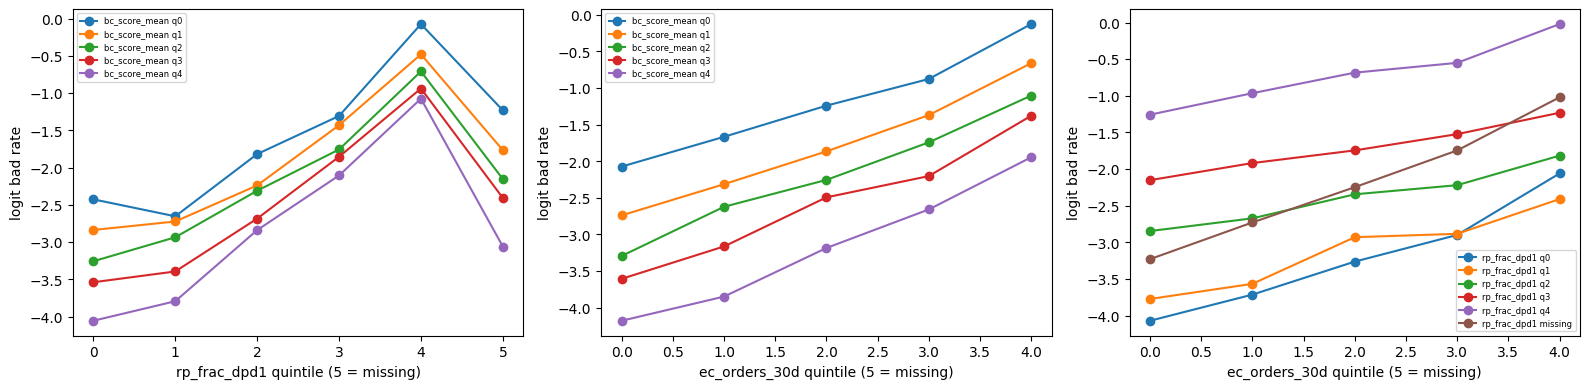

In [19]:
def logit_lines(ax, a, b, q=5):
    d = tr_f.select(a, b, 'target').with_columns(
        qa=(pl.col(a).rank('ordinal') * q // (pl.col(a).count() + 1)).fill_null(q),
        qb=(pl.col(b).rank('ordinal') * q // (pl.col(b).count() + 1)).fill_null(q))
    g = (d.group_by('qa', 'qb').agg(n=pl.len(), bad=pl.col('target').sum()).filter(pl.col('n') >= 100)
          .with_columns(logit=((pl.col('bad') + 1) / (pl.col('n') - pl.col('bad') + 1)).log()).sort('qa', 'qb'))
    for k in range(q + 1):
        s = g.filter(pl.col('qb') == k)
        if s.height:
            ax.plot(s['qa'], s['logit'], 'o-', label=f'{b} q{k}' if k < q else f'{b} missing')
    ax.set_xlabel(f'{a} quintile ({q} = missing)'); ax.set_ylabel('logit bad rate'); ax.legend(fontsize=6)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (a, b) in enumerate([('rp_frac_dpd1', 'bc_score_mean'), ('ec_orders_30d', 'bc_score_mean'), ('ec_orders_30d', 'rp_frac_dpd1')]):
    logit_lines(ax[i], a, b)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'additivity.png', dpi=90); plt.show()

#### Insights

> The lines are close to parallel, so repayment, e-commerce and bureau risk combine additively in log-odds. The offline interaction test confirms that the version 1 model already captured the remaining non-additive part: no pair of families left more than noise-level structure in its residuals. The main departure is that e-commerce is steeper for thin-file customers (the missing repayment line), and a depth-3 tree can still express that. Shallow variants with stronger regularisation are therefore added next to the deep version 1 settings.

## Signal Structure Within Classes

If each feature were generated from the label alone, two features would be uncorrelated inside a class. Correlations that survive inside each class show which signals share a hidden factor. Spearman correlations are computed separately for good and bad loans.

target=0: pp_mean vs ec_accel_30d: +0.52
target=0: pp_mean vs rp_frac_dpd1: +0.37
target=0: bc_score_mean vs annual_interest_rate: -0.73
target=0: pp_mean vs declared_monthly_income: +0.26
target=1: pp_mean vs ec_accel_30d: +0.52
target=1: pp_mean vs rp_frac_dpd1: +0.38
target=1: bc_score_mean vs annual_interest_rate: -0.72
target=1: pp_mean vs declared_monthly_income: +0.22


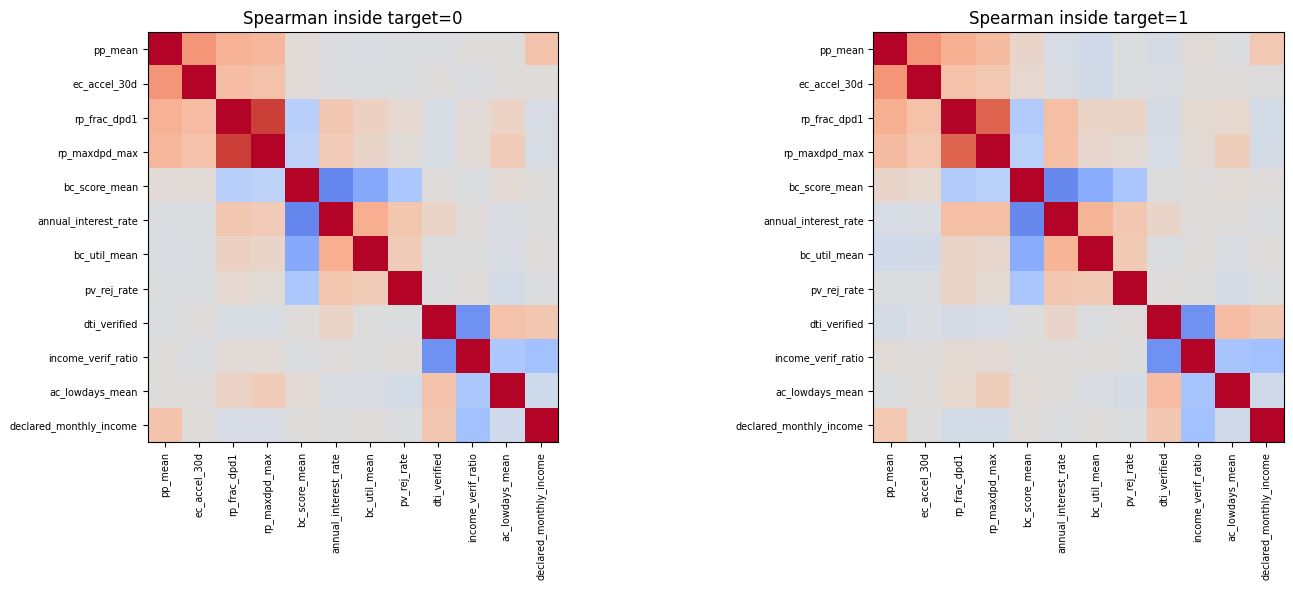

In [20]:
within_cols = ['pp_mean', 'ec_accel_30d', 'rp_frac_dpd1', 'rp_maxdpd_max', 'bc_score_mean', 'annual_interest_rate',
               'bc_util_mean', 'pv_rej_rate', 'dti_verified', 'income_verif_ratio', 'ac_lowdays_mean', 'declared_monthly_income']
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for k in (0, 1):
    sub = tr_f.filter(pl.col('target') == k).select(within_cols).to_pandas()
    cw = sub.rank().corr()
    ax[k].imshow(cw, cmap='coolwarm', vmin=-1, vmax=1)
    ax[k].set_xticks(range(len(within_cols))); ax[k].set_xticklabels(within_cols, rotation=90, fontsize=7)
    ax[k].set_yticks(range(len(within_cols))); ax[k].set_yticklabels(within_cols, fontsize=7)
    ax[k].set_title(f'Spearman inside target={k}')
    for a_, b_ in [('pp_mean', 'ec_accel_30d'), ('pp_mean', 'rp_frac_dpd1'), ('bc_score_mean', 'annual_interest_rate'), ('pp_mean', 'declared_monthly_income')]:
        print(f'target={k}: {a_} vs {b_}: {cw.loc[a_, b_]:+.2f}')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'within_class.png', dpi=90); plt.show()

#### Insights

> Inside both classes the price premium correlates about 0.52 with the spending burst and 0.35 with repayment lateness, while it is almost unrelated to the bureau score (0.04 to 0.10). Bureau score, price tier, utilisation and rejections form a second block, and income verification, low-balance days and verified DTI a third. Risk is therefore a combination of a few latent factors, each measured several times with noise. A network forms such combinations directly, which fits TabM being the best single model in every version, and a logit-space stack combines models on the scale where these factors add up.

> The premium also correlates 0.26 with declared income inside both classes: part of it is wealth, not stress. Removing that part raises its univariate KS from 0.369 to 0.376, but the version 8 models already use it through the income columns (`eda/95`).

---

# Validation Strategy <a name="5"></a>

---

Because the test set is a random sample of the training period, repeated stratified 5-fold CV is used. Every model reports per-fold KS, the out-of-fold (OOF) KS and its spread. The OOF predictions also drive a public/private split simulation that estimates how far the two leaderboards can disagree from sampling noise alone.

In [21]:
X_tr = tr_f.select(FEATURES).to_pandas()
X_te = te_f.select(FEATURES).to_pandas()
for c in CAT_COLS:
    cats = pd.Categorical(pd.concat([X_tr[c], X_te[c]])).categories
    X_tr[c] = pd.Categorical(X_tr[c], categories=cats)
    X_te[c] = pd.Categorical(X_te[c], categories=cats)
test_ids = te_f['application_id'].to_numpy()
np.save(CFG.OUTPUT_DIR / 'train_ids.npy', tr_f['application_id'].to_numpy().astype(str))
np.save(CFG.OUTPUT_DIR / 'test_ids.npy', test_ids.astype(str))

def folds(seed):
    return list(StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=seed).split(X_tr, y))

def gap_simulation(pred, n_test=30000, public_share=0.5, n_iter=300, seed=0):
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n_iter):
        idx = rng.choice(len(y), n_test, replace=False)
        cut = int(public_share * n_test)
        gaps.append(ks_score(y[idx[:cut]], pred[idx[:cut]]) - ks_score(y[idx[cut:]], pred[idx[cut:]]))
    g = np.abs(np.array(gaps))
    return float(np.median(g)), float(np.percentile(g, 95))

RESULTS = {}

def report(name, oof, fold_ks, test_pred):
    RESULTS[name] = dict(oof=oof, test=test_pred, fold_ks=fold_ks)
    med, p95 = gap_simulation(oof)
    print(f'[{name}] OOF KS={ks_score(y, oof):.4f}  AUC={roc_auc_score(y, oof):.4f}  '
          f'fold KS={np.mean(fold_ks):.4f}+-{np.std(fold_ks):.4f}  sim |pub-priv| p50={med:.4f} p95={p95:.4f}')
    np.save(CFG.OUTPUT_DIR / f'oof_{name}.npy', oof)
    np.save(CFG.OUTPUT_DIR / f'test_{name}.npy', test_pred)

---

# Gradient Boosting Models <a name="6"></a>

---

The three gradient boosting libraries are run over the same repeated folds (3 seeds x 5 folds). Each one handles missing values natively, which matters because 30% of customers lack the history tables entirely. Predictions are averaged over seeds for OOF rows and over all 15 models for the test set. Every library is trained with the deep version 1 settings and with a shallow, more regularised variant (`_s`) on the same folds and seeds.

In [22]:
def run_gbdt(name, fit_predict, seeds=None, save=True):
    seeds = seeds or CFG.GBDT_SEEDS
    oof = np.zeros(len(y))
    test_pred = np.zeros(len(X_te))
    fold_ks = []
    t0 = time.time()
    for seed in seeds:
        for k, (tri, vai) in enumerate(folds(seed)):
            pv, pt = fit_predict(tri, vai, seed)
            oof[vai] += pv / len(seeds)
            test_pred += pt / (len(seeds) * CFG.N_FOLDS)
            fold_ks.append(ks_score(y[vai], pv))
            rest_min = (time.time() - t0) / len(fold_ks) * (len(seeds) * CFG.N_FOLDS - len(fold_ks)) / 60
            if rest_min > minutes_left() - CFG.BLEND_RESERVE_MIN:
                print(f'  {name} dropped: {rest_min:.0f} more minutes needed, {minutes_left():.0f} left before the deadline')
                return None, None
        print(f'  {name} seed {seed}: fold KS {np.round(fold_ks[-CFG.N_FOLDS:], 4)}  ({time.time() - t0:.0f}s)')
    if save:
        report(name, oof, fold_ks, test_pred)
    return oof, fold_ks

## LightGBM

LightGBM uses native categorical splits and early stopping on validation AUC. AUC is only a proxy for KS (the version 7 review found model pairs that order differently on the two), but it is far less noisy as a stopping signal.

In [23]:
LGB_MODELS = []

def make_lgb_fit(params, cols=None, keep=False):
    cols = cols or FEATURES
    cats = [c for c in CAT_COLS if c in cols]
    def fit(tri, vai, seed):
        dtr = lgb.Dataset(X_tr.iloc[tri][cols], y[tri], categorical_feature=cats)
        dva = lgb.Dataset(X_tr.iloc[vai][cols], y[vai], categorical_feature=cats, reference=dtr)
        m = lgb.train({**params, 'seed': seed}, dtr, CFG.N_ROUNDS, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOP, verbose=False)])
        if keep:
            LGB_MODELS.append(m)
        return (m.predict(X_tr.iloc[vai][cols], num_iteration=m.best_iteration),
                m.predict(X_te[cols], num_iteration=m.best_iteration))
    return fit

if CFG.USE_LGB:
    run_gbdt('lgb', make_lgb_fit(CFG.LGB_PARAMS, keep=True))
    run_gbdt('lgb_s', make_lgb_fit(CFG.LGB_SHALLOW))

  lgb seed 42: fold KS [0.5202 0.5354 0.5376 0.5231 0.5089]  (100s)
  lgb seed 7: fold KS [0.5264 0.526  0.5238 0.5308 0.5191]  (197s)
  lgb seed 2026: fold KS [0.5287 0.5126 0.5283 0.5208 0.5351]  (289s)
[lgb] OOF KS=0.5248  AUC=0.8447  fold KS=0.5251+-0.0079  sim |pub-priv| p50=0.0091 p95=0.0282
  lgb_s seed 42: fold KS [0.5183 0.5332 0.5453 0.5199 0.5079]  (97s)
  lgb_s seed 7: fold KS [0.5235 0.5231 0.5224 0.5278 0.5177]  (190s)
  lgb_s seed 2026: fold KS [0.5321 0.5197 0.5289 0.5217 0.5329]  (292s)
[lgb_s] OOF KS=0.5245  AUC=0.8451  fold KS=0.5250+-0.0085  sim |pub-priv| p50=0.0090 p95=0.0278


## Feature Ablation

The version 5 features were selected offline from a residual analysis, which is only a proxy. This cell measures them directly: the shallow LightGBM is trained on one seed with the version 3 features and with all features, on identical folds. The per-fold difference is paired, so fold-to-fold noise cancels. (In version 2 the same check gave +0.0046 KS with 5 of 5 folds improved.)

In [24]:
if CFG.USE_LGB:
    ab = {}
    for tag, cols in [('v3', V3_FEATURES), ('v3+v5', FEATURES)]:
        oof_ab, fk_ab = run_gbdt(f'ablation {tag}', make_lgb_fit(CFG.LGB_SHALLOW, cols), seeds=[CFG.SEED], save=False)
        ab[tag] = (ks_score(y, oof_ab), np.array(fk_ab))
    d = ab['v3+v5'][1] - ab['v3'][1]
    print(f"OOF KS v3 features {ab['v3'][0]:.4f} -> v3+v5 features {ab['v3+v5'][0]:.4f}")
    print(f'per-fold KS gain: {np.round(d, 4)}  mean={d.mean():+.4f}  folds improved {int((d > 0).sum())}/{len(d)}')

  ablation v3 seed 42: fold KS [0.5053 0.5182 0.5256 0.5094 0.4947]  (116s)
  ablation v3+v5 seed 42: fold KS [0.5183 0.5332 0.5453 0.5199 0.5079]  (95s)
OOF KS v3 features 0.5070 -> v3+v5 features 0.5226
per-fold KS gain: [0.0129 0.0151 0.0197 0.0105 0.0132]  mean=+0.0143  folds improved 5/5


The gain importance of the deep LightGBM models shows which feature families carry the ranking.

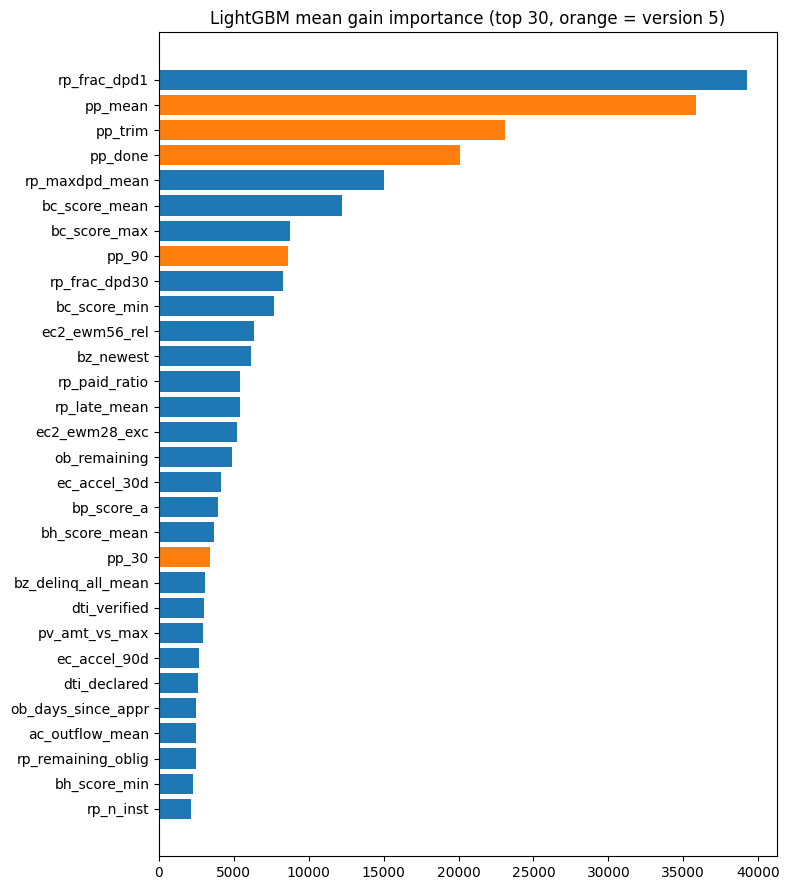

In [25]:
if LGB_MODELS:
    imp = pd.DataFrame({'feature': LGB_MODELS[0].feature_name(),
                        'gain': np.mean([m.feature_importance('gain') for m in LGB_MODELS], axis=0)})
    imp = imp.sort_values('gain', ascending=False).head(30)
    fig, ax = plt.subplots(figsize=(8, 9))
    ax.barh(imp['feature'][::-1], imp['gain'][::-1], color=['C1' if f.startswith(V5_PREFIX) else 'C0' for f in imp['feature'][::-1]])
    ax.set_title('LightGBM mean gain importance (top 30, orange = version 5)')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'lgb_importance.png', dpi=90); plt.show()

## XGBoost

XGBoost runs the histogram algorithm on the GPU with native categorical support. The test matrix is built once per feature layout.

In [26]:
D_TE = xgb.DMatrix(X_te, enable_categorical=True)

def make_xgb_fit(params):
    def fit(tri, vai, seed):
        dtr = xgb.DMatrix(X_tr.iloc[tri], y[tri], enable_categorical=True)
        dva = xgb.DMatrix(X_tr.iloc[vai], y[vai], enable_categorical=True)
        m = xgb.train({**params, 'seed': seed}, dtr, CFG.N_ROUNDS, evals=[(dva, 'va')],
                      early_stopping_rounds=CFG.EARLY_STOP, verbose_eval=False)
        it = (0, m.best_iteration + 1)
        return m.predict(dva, iteration_range=it), m.predict(D_TE, iteration_range=it)
    return fit

if CFG.USE_XGB:
    run_gbdt('xgb', make_xgb_fit(CFG.XGB_PARAMS))
    run_gbdt('xgb_s', make_xgb_fit(CFG.XGB_SHALLOW))

  xgb seed 42: fold KS [0.5191 0.5341 0.5399 0.5179 0.5122]  (48s)
  xgb seed 7: fold KS [0.5287 0.5179 0.5284 0.5292 0.5156]  (92s)
  xgb seed 2026: fold KS [0.5335 0.5151 0.5254 0.5234 0.531 ]  (138s)
[xgb] OOF KS=0.5224  AUC=0.8450  fold KS=0.5248+-0.0079  sim |pub-priv| p50=0.0087 p95=0.0252
  xgb_s seed 42: fold KS [0.5181 0.5356 0.545  0.5202 0.5074]  (41s)
  xgb_s seed 7: fold KS [0.5278 0.5231 0.5282 0.5253 0.5175]  (84s)
  xgb_s seed 2026: fold KS [0.5299 0.5207 0.5302 0.5232 0.5345]  (125s)
[xgb_s] OOF KS=0.5241  AUC=0.8450  fold KS=0.5258+-0.0087  sim |pub-priv| p50=0.0088 p95=0.0280


## CatBoost

CatBoost trains on the GPU with ordered target statistics for the four categorical columns, which are passed as strings. Its symmetric trees already have an additive flavour, so the shallow variant uses depth 4.

In [27]:
def as_str(df):
    out = df.copy()
    for c in CAT_COLS:
        out[c] = out[c].astype(str)
    return out

XC_TR, XC_TE = as_str(X_tr), as_str(X_te)

CAT_DEVICE = {'task_type': CFG.CAT_PARAMS['task_type']}

def make_cat_fit(params):
    def fit(tri, vai, seed):
        pool_tr = Pool(XC_TR.iloc[tri], y[tri], cat_features=CAT_COLS)
        pool_va = Pool(XC_TR.iloc[vai], y[vai], cat_features=CAT_COLS)
        try:
            m = CatBoostClassifier(**{**params, **CAT_DEVICE}, random_seed=seed)
            m.fit(pool_tr, eval_set=pool_va)
        except Exception as e:
            if CAT_DEVICE['task_type'] != 'GPU':
                raise
            print('  CatBoost GPU failed, falling back to CPU:', repr(e)[:120])
            CAT_DEVICE['task_type'] = 'CPU'
            m = CatBoostClassifier(**{**params, **CAT_DEVICE}, random_seed=seed)
            m.fit(pool_tr, eval_set=pool_va)
        return m.predict_proba(XC_TR.iloc[vai])[:, 1], m.predict_proba(XC_TE)[:, 1]
    return fit

if CFG.USE_CAT:
    run_gbdt('cat', make_cat_fit(CFG.CAT_PARAMS))
    run_gbdt('cat_s', make_cat_fit(CFG.CAT_SHALLOW))

  cat seed 42: fold KS [0.5161 0.5286 0.5397 0.5192 0.5134]  (156s)
  cat seed 7: fold KS [0.528  0.5232 0.5192 0.5268 0.5148]  (292s)
  cat seed 2026: fold KS [0.5293 0.512  0.5256 0.5256 0.5301]  (439s)
[cat] OOF KS=0.5216  AUC=0.8436  fold KS=0.5234+-0.0073  sim |pub-priv| p50=0.0093 p95=0.0289
  cat_s seed 42: fold KS [0.5151 0.5274 0.5389 0.5203 0.5091]  (149s)
  cat_s seed 7: fold KS [0.5272 0.5238 0.5151 0.5248 0.5155]  (318s)
  cat_s seed 2026: fold KS [0.5254 0.5128 0.5263 0.5258 0.5328]  (457s)
[cat_s] OOF KS=0.5213  AUC=0.8433  fold KS=0.5227+-0.0077  sim |pub-priv| p50=0.0090 p95=0.0282


#### Insights

> Reference points from version 8 (T4, same features, folds and seeds): deep LightGBM 0.5239, shallow LightGBM 0.5245, XGBoost 0.5224 / 0.5241, CatBoost 0.5213 / 0.5208, equal-weight trees 0.5231. The fold standard deviation is about 0.008, so differences of a few thousandths between libraries are noise; the trees serve the blend as a stable, well-understood core.

---

# Foundation and Neural Models <a name="7"></a>

---

This section adds models that rank customers differently from the trees. TabM is a neural network trained from scratch, an efficient ensemble of 32 MLPs that share most weights; it has been the strongest single model in every version (0.5257 in version 8). RealMLP is a second supervised network with its own tuned defaults (`RealMLP-TD` from PyTabKit). TabPFN-3.5 and Causilo are pretrained in-context learners: the training rows are the prompt, and no gradient step is taken on this data. Version 8 measured them at 0.5186 and 0.5241 (Causilo gained 0.0015 from typed categorical columns).

TabICLv2 and EXAONE are not run. TabICLv2 scores all 44,000 query rows of a fold in one call and ran out of GPU memory at every context size before the kernel died. EXAONE at the 12,000-row context a T4 can hold scored 0.5120 against 0.5189 for LightGBM on identical rows.

The models run in order of expected value and risk: TabM, then a provisional submission, then the periodic TabM, RealMLP, TabPFN-3.5 and Causilo. A failure in any of the later models cannot remove the file already written.

## Feature Subset and Context

Inside each fold, numeric features are ranked by univariate KS on the fold's training part only, which avoids selection leakage. Near-duplicates (Spearman correlation above 0.95) are dropped greedily (a correlation that cannot be computed, for example between two columns that are never observed together, counts as zero), and the top numeric columns are kept with the categorical codes: 100 for TabPFN and Causilo.

`run_fm` spreads the five folds over both T4 GPUs, one worker thread per GPU (folds 0, 2, 4 on the first and 1, 3 on the second). Each fold is a separate model, so the result equals a sequential run. Before a fold starts, the longest fold time seen so far is compared with the time left before the deadline, and the model is dropped if the fold could not finish. When a fold runs out of GPU memory, its context halves and the fold is retried. Out-of-memory messages from PyTorch and from the in-context libraries are both recognised; any other error stops the model and is printed.

In [28]:
VIEWS = {'hand': (X_tr, X_te, NUM_COLS, CAT_COLS)}
MEMORY_ERRORS = ('out of memory', 'cannot fit')

def select_fm_features(idx, n_num=None, view='hand'):
    n_num = n_num or CFG.FM_N_FEATURES
    XA, _, num, cats = VIEWS[view]
    sub, yy = XA.iloc[idx], y[idx]
    ranked = sorted(num, key=lambda c: -ks_nan(yy, sub[c].to_numpy(dtype=float)))[:2 * n_num]
    corr = sub[ranked].rank().corr().abs().fillna(0.0)
    keep = []
    for c in ranked:
        if all(corr.loc[c, k] < 0.95 for k in keep):
            keep.append(c)
        if len(keep) == n_num:
            break
    return keep + cats

def fm_matrix(df, cols):
    out = df[cols].copy()
    for c in cols:
        if isinstance(out[c].dtype, pd.CategoricalDtype):
            out[c] = out[c].cat.codes
    return out.to_numpy(dtype=np.float32)

def stratified_subsample(idx, n, seed):
    if len(idx) <= n:
        return idx
    rng = np.random.default_rng(seed)
    pos, neg = idx[y[idx] == 1], idx[y[idx] == 0]
    k = int(round(n * len(pos) / len(idx)))
    return rng.permutation(np.r_[rng.choice(pos, k, replace=False), rng.choice(neg, n - k, replace=False)])

def predict_chunks(m, X):
    if getattr(m, 'whole_query', False):
        return m.predict_proba(X)[:, 1]
    return np.concatenate([m.predict_proba(X[i:i + CFG.FM_CHUNK])[:, 1] for i in range(0, len(X), CFG.FM_CHUNK)])

def run_fm(name, make_model, max_context, n_num=None, view='hand', devices=None, fold_min=0.0):
    XA, XB, _, cats = VIEWS[view]
    devices = devices or CFG.GPUS[:1]
    split = folds(CFG.SEED)
    oof, test_parts, fold_ks = np.zeros(len(y)), {}, {}
    state = {'fold_s': fold_min * 60, 'stop': False}

    def run_fold(k, dev):
        tri, vai = split[k]
        if state['stop'] or state['fold_s'] / 60 > minutes_left() - CFG.BLEND_RESERVE_MIN:
            state['stop'] = True
            return
        t_fold = time.time()
        cols = select_fm_features(tri, n_num, view)
        cat_idx = [cols.index(c) for c in cats]
        Xq = np.vstack([fm_matrix(XA.iloc[vai], cols), fm_matrix(XB, cols)])
        ctx = max_context
        while True:
            ci, m = stratified_subsample(tri, ctx, CFG.SEED + k), None
            try:
                m = make_model(cat_idx, dev)
                m.fit(fm_matrix(XA.iloc[ci], cols), y[ci])
                pq = predict_chunks(m, Xq)
                break
            except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
                if not any(t in str(e).lower() for t in MEMORY_ERRORS):
                    raise
                del m; gc.collect(); torch.cuda.empty_cache()
                ctx //= 2
                print(f'  {name} fold {k}: out of GPU memory on {dev} -> context reduced to {ctx}')
                if ctx < 2000:
                    raise
        oof[vai], test_parts[k] = pq[:len(vai)], pq[len(vai):]
        fold_ks[k] = ks_score(y[vai], oof[vai])
        state['fold_s'] = max(state['fold_s'], time.time() - t_fold)
        print(f'  {name} fold {k} on {dev}: KS={fold_ks[k]:.4f} ctx={len(ci)} feats={len(cols)} '
              f'({time.time() - t_fold:.0f}s, {minutes_left():.0f} min left)', flush=True)
        del m; gc.collect(); torch.cuda.empty_cache()

    def worker(i):
        with torch.cuda.device(devices[i]):
            for k in range(i, CFG.N_FOLDS, len(devices)):
                try:
                    run_fold(k, devices[i])
                except Exception:
                    state['stop'] = True
                    raise

    with ThreadPoolExecutor(len(devices)) as ex:
        list(ex.map(worker, range(len(devices))))
    if len(fold_ks) < CFG.N_FOLDS:
        print(f'  {name} dropped: {len(fold_ks)} of {CFG.N_FOLDS} folds finished before the deadline')
        return
    report(name, oof, [fold_ks[k] for k in range(CFG.N_FOLDS)],
           np.mean([test_parts[k] for k in range(CFG.N_FOLDS)], axis=0))

## TabM

A neural network needs inputs on a common scale, without missing values. The offline checks (`eda/32_nn_prep_verify.py`) confirmed the preparation below on the real data:

- Every numeric column is mapped through its mid-rank empirical CDF to a standard normal. It preserves the order of values, so the univariate KS is identical to the raw column. A value shared by many rows lands in the middle of its tie block.
- Missing values become 0, the median of the normal scale. One indicator per distinct missingness pattern tells the network which tables are absent.

The map is fitted inside every fold on the training part only, so no validation row influences its own input.

`tabm` uses piecewise-linear embeddings with 48 quantile bins per feature and is trained over 5 seeds x 5 folds (the first 3 seeds are the tree seeds), with up to 60 epochs (patience 8). `tabm_p` (periodic embeddings, learned sine and cosine features) uses the 3 tree seeds and runs after the provisional submission. Each of the 32 members is trained on its own loss, early stopping uses validation AUC on selected applications, and the members' probabilities are averaged.

In [29]:
def nn_prep(train: np.ndarray, test: np.ndarray):
    train = np.where(np.isfinite(train), train, np.nan)
    test = np.where(np.isfinite(test), test, np.nan)
    ref = [np.sort(train[~np.isnan(train[:, j]), j]) for j in range(train.shape[1])]
    keep = [j for j, s in enumerate(ref) if len(s) and s[0] < s[-1]]

    def transform(a):
        out = np.zeros((a.shape[0], len(keep)), np.float32)
        for i, j in enumerate(keep):
            s, x = ref[j], a[:, j]
            m = ~np.isnan(x)
            u = (np.searchsorted(s, x[m], side="left") + np.searchsorted(s, x[m], side="right")) / (2 * len(s))
            out[m, i] = np.clip(ndtri(np.clip(u, 0.5 / len(s), 1 - 0.5 / len(s))), -5, 5)
        return out

    miss_tr, miss_te = np.isnan(train[:, keep]), np.isnan(test[:, keep])
    seen, ind_cols = set(), []
    for i in range(miss_tr.shape[1]):
        key = np.packbits(miss_tr[:, i]).tobytes()
        if miss_tr[:, i].any() and key not in seen:
            seen.add(key)
            ind_cols.append(i)
    Xtr = np.hstack([transform(train), miss_tr[:, ind_cols].astype(np.float32)])
    Xte = np.hstack([transform(test), miss_te[:, ind_cols].astype(np.float32)])
    return Xtr, Xte, {"kept": keep, "indicator_of": ind_cols}

In [30]:
A_TR, A_TE = X_tr[NUM_COLS].to_numpy(dtype=float), X_te[NUM_COLS].to_numpy(dtype=float)
CARDS = [len(X_tr[c].cat.categories) for c in CAT_COLS]
XCAT_TR = np.column_stack([X_tr[c].cat.codes.to_numpy() for c in CAT_COLS]).astype(np.int64)
XCAT_TE = np.column_stack([X_te[c].cat.codes.to_numpy() for c in CAT_COLS]).astype(np.int64)
tri0, vai0 = folds(CFG.SEED)[0]
xa, xb, info0 = nn_prep(A_TR[tri0], np.vstack([A_TR[vai0], A_TE]))
print(f'fold-local TabM input on fold 0: {xa.shape[1]} columns ({len(info0["kept"])} features + '
      f'{len(info0["indicator_of"])} missing groups), finite={np.isfinite(xa).all() and np.isfinite(xb).all()}')
del xa, xb

fold-local TabM input on fold 0: 266 columns (228 features + 38 missing groups), finite=True


In [31]:
DEV = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

def tabm_predict(model, xn, xc):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(xn[i:i + 8192], xc[i:i + 8192]).squeeze(-1).float()).mean(1)
                          for i in range(0, len(xn), 8192)]).cpu().numpy()

def make_tabm_fit(embedding):
    def fit(tri, vai, seed):
        torch.manual_seed(seed)
        fit_x, rest_x, _ = nn_prep(A_TR[tri], np.vstack([A_TR[vai], A_TE]))
        xn = torch.as_tensor(fit_x, device=DEV)
        xc = torch.as_tensor(XCAT_TR[tri], device=DEV)
        vn = torch.as_tensor(rest_x[:len(vai)], device=DEV); vc = torch.as_tensor(XCAT_TR[vai], device=DEV)
        tn = torch.as_tensor(rest_x[len(vai):], device=DEV); tc = torch.as_tensor(XCAT_TE, device=DEV)
        yt = torch.as_tensor(y[tri], dtype=torch.float32, device=DEV)
        if embedding == 'ple':
            emb = rtdl_num_embeddings.PiecewiseLinearEmbeddings(
                rtdl_num_embeddings.compute_bins(xn, n_bins=CFG.TABM_BINS), d_embedding=16, activation=False, version='B')
        else:
            emb = rtdl_num_embeddings.PeriodicEmbeddings(xn.shape[1], lite=False)
        model = tabm.TabM.make(n_num_features=xn.shape[1], cat_cardinalities=CARDS, d_out=1, num_embeddings=emb).to(DEV)
        opt = torch.optim.AdamW(model.parameters(), lr=CFG.TABM_LR, weight_decay=CFG.TABM_WD)
        best, best_state, wait = -1.0, None, 0
        for epoch in range(CFG.TABM_EPOCHS):
            model.train()
            for idx in torch.randperm(len(xn), device=DEV).split(CFG.TABM_BATCH):
                out = model(xn[idx], xc[idx]).squeeze(-1)
                loss = torch.nn.functional.binary_cross_entropy_with_logits(out, yt[idx].unsqueeze(1).expand_as(out))
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
            auc = roc_auc_score(y[vai], tabm_predict(model, vn, vc))
            if auc > best:
                best, best_state, wait = auc, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
            if wait >= CFG.TABM_PATIENCE:
                break
        model.load_state_dict(best_state)
        pv, pt = tabm_predict(model, vn, vc), tabm_predict(model, tn, tc)
        del model, opt, xn, xc, vn, vc, tn, tc; gc.collect(); torch.cuda.empty_cache()
        return pv, pt
    return fit

TABM_OK = CFG.USE_TABM and tabm is not None and torch.cuda.is_available()
if TABM_OK:
    try:
        run_gbdt('tabm', make_tabm_fit('ple'), seeds=CFG.TABM_SEEDS)
    except Exception as e:
        print('tabm skipped:', repr(e))

  tabm seed 42: fold KS [0.5181 0.5385 0.5435 0.5212 0.5071]  (629s)
  tabm seed 7: fold KS [0.528  0.5326 0.5254 0.5347 0.5179]  (1257s)
  tabm seed 2026: fold KS [0.5292 0.5177 0.5318 0.5211 0.5313]  (1856s)
  tabm seed 11: fold KS [0.5436 0.5161 0.5198 0.531  0.5131]  (2501s)
  tabm seed 99: fold KS [0.5273 0.5208 0.5182 0.5205 0.5354]  (3109s)
[tabm] OOF KS=0.5253  AUC=0.8465  fold KS=0.5258+-0.0092  sim |pub-priv| p50=0.0091 p95=0.0254


## Safety-Net Submission

The first version 8 run died inside TabICLv2 after four hours. A dead kernel leaves no traceback, but the files already written to `/kaggle/working` are kept. A provisional `submission.csv` is therefore written here from the fixed 80% trees plus 20% TabM blend, which needs no fitting (version 8: 0.5258 on held-out halves). Section 9 overwrites it with the chosen blend.

In [32]:
unit_rank = lambda p: rankdata(p) / len(p)
safe = np.mean([unit_rank(RESULTS[n]['test']) for n in ('lgb', 'lgb_s', 'xgb', 'xgb_s', 'cat', 'cat_s') if n in RESULTS], axis=0)
if 'tabm' in RESULTS:
    safe = 0.8 * safe + 0.2 * unit_rank(RESULTS['tabm']['test'])
pl.DataFrame({'application_id': test_ids, 'default_probability': (safe - safe.min()) / (safe.max() - safe.min())}
             ).write_csv(CFG.OUTPUT_DIR / 'submission.csv')
print('provisional submission written:', len(safe), 'rows')

provisional submission written: 30000 rows


## TabM with Periodic Embeddings

The periodic TabM gave the blend a second, less correlated neural member in versions 6 and 7 (rank correlation 0.990 with the PLE TabM, 0.5256 in version 6). Version 8 never reached it.

In [33]:
if TABM_OK:
    try:
        run_gbdt('tabm_p', make_tabm_fit('periodic'))
    except Exception as e:
        print('tabm_p skipped:', repr(e))

  tabm_p seed 42: fold KS [0.5204 0.5319 0.5421 0.518  0.5081]  (1043s)
  tabm_p seed 7: fold KS [0.5299 0.524  0.5274 0.5301 0.517 ]  (2062s)
  tabm_p seed 2026: fold KS [0.5285 0.516  0.5257 0.5273 0.5345]  (3057s)
[tabm_p] OOF KS=0.5245  AUC=0.8458  fold KS=0.5254+-0.0082  sim |pub-priv| p50=0.0087 p95=0.0270


## RealMLP

RealMLP-TD is an MLP with tuned defaults (robust scaling, numerical embeddings, a tuned learning-rate schedule) that was competitive with gradient boosting on the PyTabKit benchmarks. It does not accept missing numbers, so each fold imputes every numeric column with its median on the training part and adds a 0/1 missing flag for every column that has missing values there; observed values stay unchanged. The four categorical columns stay categorical and are passed by name. Early stopping uses the validation part with cross-entropy, as for TabM. Two seeds are used; RealMLP trains for up to 256 epochs per fold.

In [34]:
def realmlp_frames(tri, rest):
    num = X_tr[NUM_COLS].iloc[tri]
    med = num.median()
    flag_cols = [c for c in NUM_COLS if num[c].isna().any()]
    def prep(df):
        out = df[NUM_COLS].fillna(med).fillna(0.0).astype(np.float32)
        flags = df[flag_cols].isna().astype(np.float32).add_suffix('_na')
        return pd.concat([out, flags, df[CAT_COLS].astype(str).astype('category')], axis=1)
    return prep(X_tr.iloc[tri]), [prep(d) for d in rest]

def make_realmlp_fit():
    def fit(tri, vai, seed):
        Xa, (Xv, Xt) = realmlp_frames(tri, [X_tr.iloc[vai], X_te])
        m = RealMLP_TD_Classifier(device='cuda:0', random_state=seed, n_cv=1, n_refit=0, val_metric_name='cross_entropy',
                                  use_ls=False, verbosity=0)
        m.fit(Xa, y[tri], Xv, y[vai], cat_col_names=CAT_COLS)
        pv, pt = m.predict_proba(Xv)[:, 1], m.predict_proba(Xt)[:, 1]
        del m; gc.collect(); torch.cuda.empty_cache()
        return pv, pt
    return fit

if CFG.USE_REALMLP and RealMLP_TD_Classifier is not None and torch.cuda.is_available():
    try:
        run_gbdt('realmlp', make_realmlp_fit(), seeds=CFG.REALMLP_SEEDS)
    except Exception as e:
        print('RealMLP skipped:', repr(e))

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
`Trainer.fit` stopped: `max_epochs=256` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics 

  realmlp seed 42: fold KS [0.5188 0.5339 0.5365 0.5224 0.5105]  (2132s)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
`Trainer.fit` stopped: `max_epochs=256` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics 

  realmlp seed 7: fold KS [0.5285 0.5252 0.5228 0.5282 0.5129]  (4280s)
[realmlp] OOF KS=0.5223  AUC=0.8454  fold KS=0.5240+-0.0079  sim |pub-priv| p50=0.0082 p95=0.0266


## TabPFN-3.5

TabPFN-3.5 receives the full training fold (about 56,000 rows) and the 100 strongest non-redundant hand-made columns, including the price premium. `fit_mode='fit_with_cache'` encodes the context once into a key-value cache and reuses it for all validation and test rows. Two folds run at a time, one per GPU (version 8: about 15 minutes in total). A tiny fit on one GPU first downloads the weights, so the two threads never download them at the same time.

In [35]:
def make_tabpfn(cat_idx, device):
    m = TabPFNClassifier(n_estimators=CFG.FM_N_EST, device=device, fit_mode='fit_with_cache', ignore_pretraining_limits=True,
                         categorical_features_indices=cat_idx, random_state=CFG.SEED)
    m.whole_query = True
    return m

if CFG.USE_TABPFN and TabPFNClassifier is not None and torch.cuda.is_available():
    try:
        make_tabpfn([], CFG.GPUS[0]).fit(np.random.default_rng(0).random((100, 3)), np.arange(100) % 2)
        print(f'TabPFN-3.5 on the hand-made features, folds split over {CFG.GPUS}')
        run_fm('tabpfn', make_tabpfn, CFG.FM_MAX_CONTEXT, devices=CFG.GPUS)
    except Exception as e:
        print('TabPFN skipped:', repr(e))
    gc.collect(); torch.cuda.empty_cache()

tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

TabPFN-3.5 on the hand-made features, folds split over ['cuda:0', 'cuda:1']
  tabpfn fold 1 on cuda:1: KS=0.5303 ctx=56000 feats=104 (277s, 461 min left)
  tabpfn fold 0 on cuda:0: KS=0.5194 ctx=56000 feats=104 (279s, 461 min left)
  tabpfn fold 2 on cuda:0: KS=0.5346 ctx=56000 feats=104 (277s, 457 min left)
  tabpfn fold 3 on cuda:1: KS=0.5206 ctx=56000 feats=104 (284s, 457 min left)
  tabpfn fold 4 on cuda:0: KS=0.5104 ctx=56000 feats=104 (274s, 452 min left)
[tabpfn] OOF KS=0.5187  AUC=0.8425  fold KS=0.5231+-0.0086  sim |pub-priv| p50=0.0091 p95=0.0267


## Causilo

Causilo is a causally pretrained in-context learner. `CausiloModel` turns the float matrix back into a DataFrame and gives the four categorical columns a pandas categorical dtype, with the categories seen in the training context, as its documentation requires for numeric category codes. Unseen categories are handled by Causilo's fitted schema.

In [36]:
class CausiloModel:
    def __init__(self, cat_idx, device):
        self.cat_idx = cat_idx
        self.m = CausiloClassifier(n_estimators=CFG.FM_N_EST, random_state=CFG.SEED, device=device)

    def frame(self, X):
        d = pd.DataFrame(X, columns=[f'f{j}' for j in range(X.shape[1])])
        for j in self.cat_idx:
            d[f'f{j}'] = pd.Categorical(d[f'f{j}'], categories=self.cats[j])
        return d

    def fit(self, X, yy):
        self.cats = {j: np.unique(X[:, j][np.isfinite(X[:, j])]) for j in self.cat_idx}
        self.m.fit(self.frame(X), yy)
        return self

    def predict_proba(self, X):
        return np.asarray(self.m.predict_proba(self.frame(X)))

if CFG.USE_CAUSILO and CausiloClassifier is not None and torch.cuda.is_available():
    try:
        run_fm('causilo', CausiloModel, CFG.FM_MAX_CONTEXT, devices=CFG.GPUS)
    except Exception as e:
        print('Causilo skipped:', repr(e))
    gc.collect(); torch.cuda.empty_cache()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

  causilo fold 1 on cuda:1: KS=0.5302 ctx=56000 feats=104 (337s, 446 min left)
  causilo fold 0 on cuda:0: KS=0.5219 ctx=56000 feats=104 (343s, 446 min left)


...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

  causilo fold 3 on cuda:1: KS=0.5228 ctx=56000 feats=104 (341s, 441 min left)
  causilo fold 2 on cuda:0: KS=0.5455 ctx=56000 feats=104 (336s, 441 min left)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

  causilo fold 4 on cuda:0: KS=0.5085 ctx=56000 feats=104 (336s, 435 min left)
[causilo] OOF KS=0.5239  AUC=0.8444  fold KS=0.5258+-0.0121  sim |pub-priv| p50=0.0090 p95=0.0260


#### Insights

> Reference points from version 8 (T4): equal-weight trees 0.5231, TabM 0.5257 (3 seeds), TabPFN-3.5 0.5186, Causilo 0.5241, blend 0.5277 on held-out halves. A non-tree model does not need to beat the trees to help. What matters is whether it ranks some customers differently and correctly, which the blend below measures on held-out halves.

---

# Ensemble and KS Stability <a name="8"></a>

---

KS depends only on the ranking, so the classic blend converts each model's predictions to normalised ranks. Four rank candidates are compared: the equal-weight blend of the six tree models, a fixed 80% trees plus 20% TabM blend (both need no fitting), greedy ensemble selection (Caruana et al.), which adds with replacement, `ENS_ITERS` times, the model that most raises OOF KS, and bagged greedy selection, which repeats greedy on `ENS_BAGS` random half-samples and averages the weights (the winner of versions 7 and 8).

Version 9 adds a fifth candidate, **logit stacking**: an L2-regularised logistic regression on the logits of all models. The best pooled KS comes from a score that orders customers by their true bad probability, and the within-class analysis showed that risk adds up on the log-odds scale. A rank average ignores how sure each model is about each customer; the stack keeps it. Offline on the saved version 8 predictions it beat the rank blend on 5 of 6 held-out halves (+0.0008).

Every candidate is scored on held-out halves: whatever is fitted on one half is scored on the other, and the two scores are averaged. The candidate with the best held-out score is used. Each non-tree model is also scored at a fixed 20% share, which shows its contribution without any fitting.

In [37]:
names = list(RESULTS)
R_OOF = np.column_stack([rankdata(RESULTS[n]['oof']) / len(y) for n in names])
R_TE = np.column_stack([rankdata(RESULTS[n]['test']) / len(X_te) for n in names])
print(pd.DataFrame(R_OOF, columns=names).corr().round(3))

def best_weights(rows):
    counts, cur = np.zeros(len(names)), np.zeros(len(rows))
    for it in range(CFG.ENS_ITERS):
        cand = [(cur * it + R_OOF[rows, j]) / (it + 1) for j in range(len(names))]
        j = int(np.argmax([ks_score(y[rows], c) for c in cand]))
        counts[j] += 1
        cur = cand[j]
    return counts / counts.sum()

TREES = ('lgb', 'lgb_s', 'xgb', 'xgb_s', 'cat', 'cat_s')
w_tree = np.array([1.0 if n in TREES else 0.0 for n in names]); w_tree /= w_tree.sum()
w_fix = 0.8 * w_tree + 0.2 * np.array([1.0 if n == 'tabm' else 0.0 for n in names]) if 'tabm' in names else w_tree
half = np.random.default_rng(0).permutation(len(y))
a, b = half[: len(y) // 2], half[len(y) // 2:]
w_a, w_b = best_weights(a), best_weights(b)
def held(wa, wb=None):
    wb = wa if wb is None else wb
    return (ks_score(y[b], R_OOF[b] @ wa) + ks_score(y[a], R_OOF[a] @ wb)) / 2
def bagged_weights(rows, seed=0):
    rng = np.random.default_rng(seed)
    return np.mean([best_weights(rng.choice(rows, len(rows) // 2, replace=False)) for _ in range(CFG.ENS_BAGS)], axis=0)

def to_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-5, 1 - 1e-5)
    return np.log(p / (1 - p))

L_OOF = np.column_stack([to_logit(RESULTS[n]['oof']) for n in names])
L_TE = np.column_stack([to_logit(RESULTS[n]['test']) for n in names])

def fit_stack(rows, l2=1.0, iters=25):
    X = np.column_stack([np.ones(len(rows)), L_OOF[rows]])
    w, pen = np.zeros(X.shape[1]), np.r_[0.0, np.full(L_OOF.shape[1], l2)]
    for _ in range(iters):
        pr = 1 / (1 + np.exp(-X @ w))
        grad = X.T @ (pr - y[rows]) + pen * w
        hess = (X * (pr * (1 - pr))[:, None]).T @ X + np.diag(pen)
        w -= np.linalg.solve(hess, grad)
    return w[1:]

s_a, s_b = fit_stack(a), fit_stack(b)
w_stack = fit_stack(np.arange(len(y)))
rank_blend = lambda w: (R_OOF @ w, R_TE @ w)
cands = {'equal-weight trees': (held(w_tree), rank_blend(w_tree)),
         '80% trees + 20% TabM': (held(w_fix), rank_blend(w_fix)),
         'greedy': (held(w_a, w_b), rank_blend(best_weights(np.arange(len(y))))),
         'bagged greedy': (held(bagged_weights(a), bagged_weights(b)), rank_blend(bagged_weights(np.arange(len(y))))),
         'logit stacking': ((ks_score(y[b], L_OOF[b] @ s_a) + ks_score(y[a], L_OOF[a] @ s_b)) / 2, (L_OOF @ w_stack, L_TE @ w_stack))}
for k_, (sc, _) in cands.items():
    print(f'held-out halves: {k_:<22} {sc:.4f}')
print('greedy weights fitted per half:', dict(zip(names, np.round(w_a, 2))), dict(zip(names, np.round(w_b, 2))))
print('logit stacking coefficients:', dict(zip(names, np.round(w_stack, 3))))
choice = max(cands, key=lambda k_: cands[k_][0])
blend_oof, blend_te = cands[choice][1]
print('chosen:', choice)
for n in [n for n in names if n not in TREES]:
    j = names.index(n)
    w_add = 0.8 * w_tree + 0.2 * np.eye(len(names))[j]
    print(f'  adding {n} at 20% to the tree blend: held-out halves {held(w_add):.4f} (trees alone {held(w_tree):.4f})')

for n in names:
    print(f'  {n:<10} OOF KS {ks_score(y, RESULTS[n]["oof"]):.4f}')
print(f'  BLEND    OOF KS {ks_score(y, blend_oof):.4f} in-sample, {cands[choice][0]:.4f} on held-out halves   (version 8: 0.5277 held-out, 0.5231 equal-weight trees)')
pd.DataFrame({'application_id': tr_f['application_id'].to_list(), 'target': y, 'blend': blend_oof,
              **{n: RESULTS[n]['oof'] for n in names}}).to_parquet(CFG.OUTPUT_DIR / 'oof_all.parquet', index=False)
pd.DataFrame({'application_id': test_ids, 'blend': blend_te,
              **{n: RESULTS[n]['test'] for n in names}}).to_parquet(CFG.OUTPUT_DIR / 'test_all.parquet', index=False)

           lgb  lgb_s    xgb  xgb_s    cat  cat_s   tabm  tabm_p  realmlp  \
lgb      1.000  0.995  0.997  0.996  0.984  0.984  0.986   0.984    0.983   
lgb_s    0.995  1.000  0.996  0.999  0.986  0.986  0.988   0.986    0.985   
xgb      0.997  0.996  1.000  0.997  0.985  0.984  0.987   0.985    0.984   
xgb_s    0.996  0.999  0.997  1.000  0.986  0.986  0.988   0.986    0.986   
cat      0.984  0.986  0.985  0.986  1.000  0.998  0.984   0.980    0.980   
cat_s    0.984  0.986  0.984  0.986  0.998  1.000  0.984   0.979    0.979   
tabm     0.986  0.988  0.987  0.988  0.984  0.984  1.000   0.989    0.989   
tabm_p   0.984  0.986  0.985  0.986  0.980  0.979  0.989   1.000    0.985   
realmlp  0.983  0.985  0.984  0.986  0.980  0.979  0.989   0.985    1.000   
tabpfn   0.976  0.974  0.975  0.975  0.975  0.974  0.973   0.972    0.971   
causilo  0.981  0.981  0.981  0.981  0.979  0.978  0.981   0.978    0.978   

         tabpfn  causilo  
lgb       0.976    0.981  
lgb_s     0.974    0.

## KS Stability Checks

The blend is checked along four axes: per-fold KS, the simulated public/private gap at 30% and 50% public shares, KS inside the thin-file and history segments, and KS per decision month. A stable model shows small spreads on all four.

blend fold KS: [0.522  0.5379 0.5455 0.5269 0.5123]  mean=0.5289 sd=0.0117
public share 30%: simulated |KS_pub - KS_priv| median=0.0106 p95=0.0284
public share 50%: simulated |KS_pub - KS_priv| median=0.0087 p95=0.0280
thin-file     n= 21000 bad=0.117 KS=0.5009
with history  n= 49000 bad=0.144 KS=0.5357
KS by decision month: [0.524 0.53  0.516 0.569 0.543 0.528 0.565 0.537 0.5   0.553 0.527 0.515] sd=0.0198


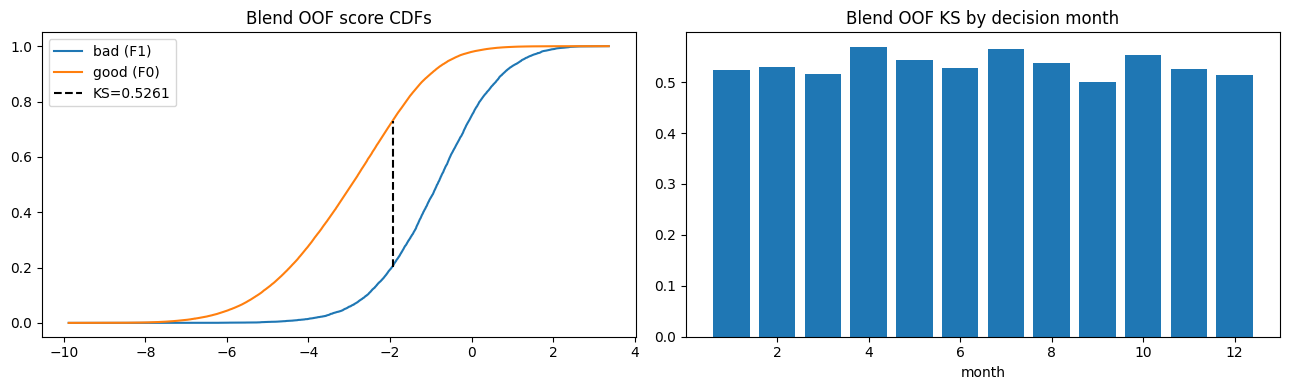

In [38]:
fk = [ks_score(y[v], blend_oof[v]) for _, v in folds(CFG.SEED)]
print(f'blend fold KS: {np.round(fk, 4)}  mean={np.mean(fk):.4f} sd={np.std(fk):.4f}')
for share in (0.3, 0.5):
    med, p95 = gap_simulation(blend_oof, public_share=share)
    print(f'public share {share:.0%}: simulated |KS_pub - KS_priv| median={med:.4f} p95={p95:.4f}')
hist = tr_f['has_history'].to_numpy()
for g, lab in [(0, 'thin-file'), (1, 'with history')]:
    msk = hist == g
    print(f'{lab:<13} n={msk.sum():>6} bad={y[msk].mean():.3f} KS={ks_score(y[msk], blend_oof[msk]):.4f}')
month = tr_f['decision_datetime'].dt.month().to_numpy()
mk = [ks_score(y[month == mth], blend_oof[month == mth]) for mth in range(1, 13)]
print('KS by decision month:', np.round(mk, 3), f'sd={np.std(mk):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s = np.sort(blend_oof)
f1 = np.searchsorted(np.sort(blend_oof[y == 1]), s, side='right') / (y == 1).sum()
f0 = np.searchsorted(np.sort(blend_oof[y == 0]), s, side='right') / (y == 0).sum()
i = np.argmax(np.abs(f1 - f0))
ax[0].plot(s, f1, label='bad (F1)'); ax[0].plot(s, f0, label='good (F0)')
ax[0].vlines(s[i], f1[i], f0[i], color='k', ls='--', label=f'KS={abs(f1[i] - f0[i]):.4f}')
ax[0].set_title('Blend OOF score CDFs'); ax[0].legend()
ax[1].bar(range(1, 13), mk); ax[1].set_title('Blend OOF KS by decision month'); ax[1].set_xlabel('month')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'ks_stability.png', dpi=90); plt.show()

#### Insights

> A simulated public/private gap of about 0.01 is the noise floor for a 30,000-row test set with about 4,000 bad loans. A leaderboard gap of that size is expected and does not indicate overfitting. A gap well above the simulated 95th percentile would point to a distribution problem rather than chance.

> Similar KS in the thin-file and history segments, and a flat month profile, show that the blend does not rely on a single sub-population or period. Those are the conditions for the public and private scores to stay close.

---

# Submission <a name="9"></a>

---

The blended test ranks are min-max scaled into [0, 1], which leaves the KS unchanged. The file is validated against every rule in the competition description before it is written.

In [39]:
def to_unit(p):
    return (p - p.min()) / (p.max() - p.min())

def write_submission(pred, path):
    sub = pl.DataFrame({'application_id': test_ids, 'default_probability': to_unit(pred)})
    assert sub.height == sample_sub.height == T['test_applications'].height
    assert sub['application_id'].n_unique() == sub.height
    assert set(sub['application_id']) == set(sample_sub['application_id'])
    assert sub['default_probability'].is_finite().all()
    assert sub['default_probability'].is_between(0, 1).all()
    sub.write_csv(path)
    print('wrote', path, sub.shape)
    return sub

submission = write_submission(blend_te, CFG.OUTPUT_DIR / 'submission.csv')
gbdt = [i for i, n in enumerate(names) if n in TREES]
if gbdt:
    write_submission(R_TE[:, gbdt].mean(1), CFG.OUTPUT_DIR / 'submission_gbdt_only.csv')
print(submission.head())

wrote /kaggle/working/submission.csv (30000, 2)
wrote /kaggle/working/submission_gbdt_only.csv (30000, 2)
shape: (5, 2)
┌────────────────────┬─────────────────────┐
│ application_id     ┆ default_probability │
│ ---                ┆ ---                 │
│ str                ┆ f64                 │
╞════════════════════╪═════════════════════╡
│ A_779e4e5a0ca90902 ┆ 0.397121            │
│ A_289cbaf13ec58feb ┆ 0.570806            │
│ A_172169d79a3f4a35 ┆ 0.417615            │
│ A_51ff46a3e1427786 ┆ 0.761241            │
│ A_bd7e505dcbebaf89 ┆ 0.633647            │
└────────────────────┴─────────────────────┘


#### Insights

> `submission.csv` is the final blend. `submission_gbdt_only.csv` is a fallback built only from the tree models, and it is useful as a second leaderboard data point. If the two differ on the public board by less than the simulated noise floor, choose the final submission by OOF KS.